# 🏙️ The 15-Minute City Profiler
## Mendiagnosis Tata Ruang Wilayah — Data Nyata dari OpenStreetMap

**Model:** K-Means Clustering dari scratch (NumPy only — tanpa scikit-learn)  
**Data:** Point of Interest (POI) langsung dari OpenStreetMap via OSMnx  

### Persiapan (jalankan sekali di terminal):
```bash
pip install osmnx geopandas folium matplotlib pandas numpy
```

---
### Pipeline:
1. ⚙️ Setup & konfigurasi kota
2. 📡 Ambil data POI dari OpenStreetMap (OSMnx)
3. 🧩 Agregasi spasial per kelurahan/grid
4. 📐 Standardisasi manual (Z-Score from scratch)
5. 🤖 K-Means from scratch + Elbow + Silhouette
6. 🔍 Profiling & diagnosis klaster
7. 🗺️ Visualisasi peta choropleth + Folium interaktif

In [1]:
# pip install osmnx geopandas folium matplotlib pandas numpy

## ⚙️ Setup

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

import osmnx as ox
import geopandas as gpd
import folium
from folium.plugins import HeatMap
from shapely.geometry import box

# Pastikan direktori output tersedia
os.makedirs('data/raw', exist_ok=True)
os.makedirs('data/processed', exist_ok=True)
os.makedirs('outputs/figures', exist_ok=True)
os.makedirs('outputs/maps', exist_ok=True)

np.random.seed(42)
print('✅ Semua library berhasil diimport & direktori kerja siap!')

✅ Semua library berhasil diimport & direktori kerja siap!


---
## ⚙️ Konfigurasi — Ganti Nama Kota di Sini

Cukup ubah variabel `CITY_NAME` untuk menganalisis kota mana pun.

In [3]:
# ============================================================
#  KONFIGURASI UTAMA
# ============================================================

# Nama wilayah — OSMnx akan otomatis mengambil polygon batasnya dari OSM
# Bisa berupa: provinsi, kota, kabupaten, kecamatan
# Contoh:
#   'DKI Jakarta, Indonesia'
#   'Kota Yogyakarta, Daerah Istimewa Yogyakarta, Indonesia'
#   'Kota Bandung, Jawa Barat, Indonesia'
#   'Kecamatan Gondokusuman, Yogyakarta, Indonesia'
PLACE_NAME = "Kota Yogyakarta, Daerah Istimewa Yogyakarta, Indonesia"

# Ukuran grid (sel analisis di dalam polygon wilayah)
# Makin besar = makin detail, tapi makin lama
# Untuk provinsi besar: 25-30 | Untuk kota kecil: 15-20
GRID_SIZE = 25

# Zona dengan total POI < nilai ini akan dibuang (noise)
MIN_POI_THRESHOLD = 1

# Batas maksimum K yang diuji
K_MAX_OVERRIDE = 6

SAVE_HTML_MAP = False

print(f'Wilayah  : {PLACE_NAME}')
print(f'Grid     : {GRID_SIZE}x{GRID_SIZE} = {GRID_SIZE**2} sel')
print(f'K max    : {K_MAX_OVERRIDE}')


Wilayah  : Kota Yogyakarta, Daerah Istimewa Yogyakarta, Indonesia
Grid     : 25x25 = 625 sel
K max    : 6


---
## 📡 Langkah 1: Ambil Data dari OpenStreetMap

OSMnx akan terhubung ke server global OpenStreetMap dan mengunduh koordinat fasilitas secara langsung.

**Estimasi waktu:** 1–5 menit tergantung kecepatan internet dan ukuran kota.

In [4]:
# ============================================================
# DEFINISI KATEGORI POI
# Setiap kategori memetakan ke tag OSM yang relevan.
# Referensi tag lengkap: https://wiki.openstreetmap.org/wiki/Map_features
# ============================================================
POI_TAGS = {
    'kesehatan': {
        'amenity': ['hospital', 'clinic', 'pharmacy', 'doctors', 'dentist', 'health_post']
    },
    'pendidikan': {
        'amenity': ['school', 'university', 'kindergarten', 'college', 'library']
    },
    'rth_taman': {
        'leisure': ['park', 'playground', 'garden', 'sports_centre', 'pitch']
    },
    'ekonomi': {
        'shop': ['supermarket', 'mall', 'convenience'],
        'amenity': ['marketplace', 'food_court']
    },
    'transportasi': {
        'highway': ['bus_stop'],
        'railway': ['station', 'halt', 'tram_stop'],
        'amenity': ['bus_station']
    },
}

poi_icons = {
    'kesehatan': '🏥', 'pendidikan': '🎓',
    'rth_taman': '🌳', 'ekonomi': '🛒', 'transportasi': '🚌'
}
poi_colors = {
    'kesehatan': '#E74C3C', 'pendidikan': '#3498DB',
    'rth_taman': '#2ECC71', 'ekonomi': '#F39C12', 'transportasi': '#9B59B6'
}

print('📋 Kategori POI yang akan diambil:')
for k, tags in POI_TAGS.items():
    all_values = [v for vals in tags.values() for v in (vals if isinstance(vals, list) else [vals])]
    print(f'  {poi_icons[k]} {k:15s}: {all_values}')

📋 Kategori POI yang akan diambil:
  🏥 kesehatan      : ['hospital', 'clinic', 'pharmacy', 'doctors', 'dentist', 'health_post']
  🎓 pendidikan     : ['school', 'university', 'kindergarten', 'college', 'library']
  🌳 rth_taman      : ['park', 'playground', 'garden', 'sports_centre', 'pitch']
  🛒 ekonomi        : ['supermarket', 'mall', 'convenience', 'marketplace', 'food_court']
  🚌 transportasi   : ['bus_stop', 'station', 'halt', 'tram_stop', 'bus_station']


In [5]:
# ============================================================
# AMBIL BATAS WILAYAH & POI DARI OSM
# ============================================================
def ambil_batas_wilayah(place_name):
    """
    Ambil polygon batas wilayah administrasi dari OSM.
    Mengembalikan GeoDataFrame + bounding box.
    """
    print(f'Mengambil batas wilayah: {place_name} ...')
    gdf = ox.geocode_to_gdf(place_name)
    polygon = gdf.geometry.iloc[0]
    bounds  = gdf.total_bounds  # (minx, miny, maxx, maxy)
    lon_min, lat_min, lon_max, lat_max = bounds
    center_lat = (lat_min + lat_max) / 2
    center_lon = (lon_min + lon_max) / 2

    print(f'  Tipe geometry : {polygon.geom_type}')
    print(f'  Luas approx   : {polygon.area * 111**2:.1f} km²')
    print(f'  BBox Lat      : [{lat_min:.4f}, {lat_max:.4f}]')
    print(f'  BBox Lon      : [{lon_min:.4f}, {lon_max:.4f}]')
    print(f'  Pusat wilayah : ({center_lat:.4f}, {center_lon:.4f})')

    return polygon, (lat_min, lat_max, lon_min, lon_max), (center_lat, center_lon)


def ambil_poi_osmnx(polygon, tags_dict):
    """
    Ambil POI dari dalam polygon batas wilayah (bukan radius km).
    Menggunakan ox.features_from_polygon — jauh lebih akurat.
    """
    poi_data = {}
    print('\nMengambil POI dari OpenStreetMap...')

    for kategori, tags in tags_dict.items():
        print(f'  {poi_icons[kategori]} {kategori}...', end=' ')
        try:
            # Ambil semua fitur OSM yang ada di DALAM polygon wilayah
            gdf = ox.features_from_polygon(polygon, tags=tags)

            # Konversi semua geometry ke titik (centroid untuk polygon/way)
            gdf = gdf.copy()
            gdf['lat'] = gdf.geometry.centroid.y
            gdf['lon'] = gdf.geometry.centroid.x
            if 'name' in gdf.columns:
                gdf['nama_poi'] = gdf['name'].fillna(kategori)
            else:
                gdf['nama_poi'] = kategori

            result = gdf[['lat', 'lon', 'nama_poi']].dropna().reset_index(drop=True)
            poi_data[kategori] = result
            print(f'{len(result)} titik')

        except Exception as e:
            print(f'gagal: {str(e)[:60]}')
            poi_data[kategori] = pd.DataFrame(columns=['lat','lon','nama_poi'])

    return poi_data


# ── JALANKAN ──────────────────────────────────────────────────
BOUNDARY_POLYGON, (LAT_MIN, LAT_MAX, LON_MIN, LON_MAX), (CENTER_LAT, CENTER_LON) = \
    ambil_batas_wilayah(PLACE_NAME)

poi_data = ambil_poi_osmnx(BOUNDARY_POLYGON, POI_TAGS)

print('\n' + '='*50)
print('RINGKASAN POI:')
total = 0
for k, df in poi_data.items():
    print(f'  {poi_icons[k]} {k:15s}: {len(df):5d} titik')
    total += len(df)
print(f'  {"TOTAL":17s}: {total:5d} titik')
print('='*50)


Mengambil batas wilayah: Kota Yogyakarta, Daerah Istimewa Yogyakarta, Indonesia ...
  Tipe geometry : Polygon
  Luas approx   : 33.9 km²
  BBox Lat      : [-7.8402, -7.7665]
  BBox Lon      : [110.3443, 110.4068]
  Pusat wilayah : (-7.8033, 110.3755)

Mengambil POI dari OpenStreetMap...
  🏥 kesehatan... 

200 titik
  🎓 pendidikan... 334 titik
  🌳 rth_taman... 

186 titik
  🛒 ekonomi... 187 titik
  🚌 transportasi... 

224 titik

RINGKASAN POI:
  🏥 kesehatan      :   200 titik
  🎓 pendidikan     :   334 titik
  🌳 rth_taman      :   186 titik
  🛒 ekonomi        :   187 titik
  🚌 transportasi   :   224 titik
  TOTAL            :  1131 titik


In [6]:
# Simpan data POI mentah ke CSV (opsional, untuk referensi)
# [DINONAKTIFKAN] — simpan file dimatikan untuk versi pengumpulan, hanya tampil inline
for kategori, df in poi_data.items():
    if len(df) > 0:
        # df.to_csv(f'data/raw/poi_{kategori}.csv', index=False)
        print(f'📊 poi_{kategori}: {len(df)} baris')

📊 poi_kesehatan: 200 baris
📊 poi_pendidikan: 334 baris
📊 poi_rth_taman: 186 baris
📊 poi_ekonomi: 187 baris
📊 poi_transportasi: 224 baris


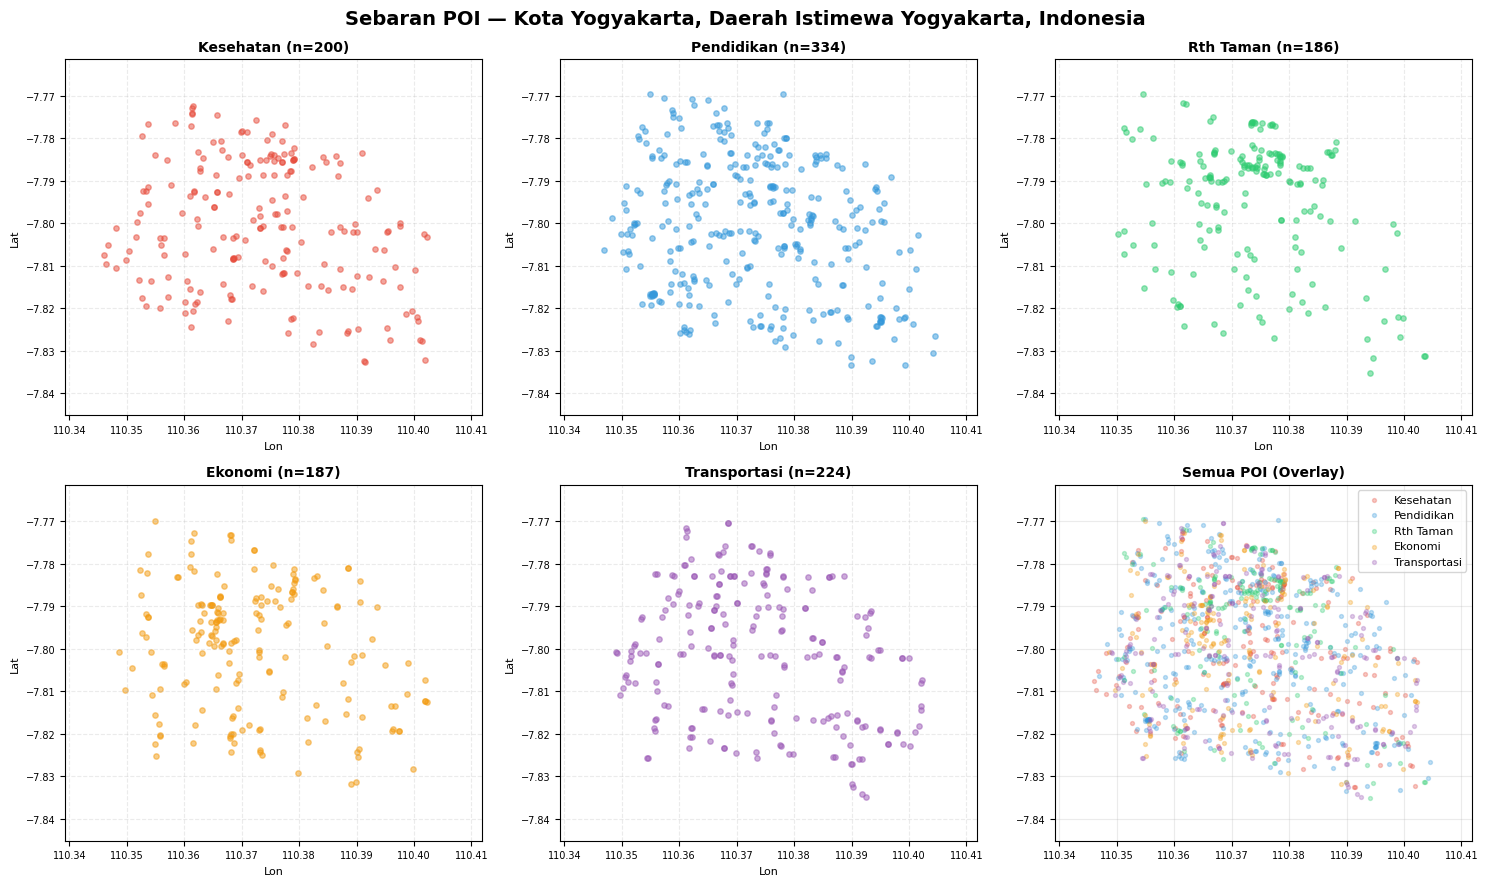

💾 Tersimpan: outputs/figures/01_sebaran_poi.png


In [7]:
# Visualisasi sebaran POI per kategori
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
fig.suptitle(f'Sebaran POI — {PLACE_NAME}', fontsize=14, fontweight='bold')

for idx, (kat, df_p) in enumerate(poi_data.items()):
    ax = axes[idx//3][idx%3]
    if len(df_p) > 0:
        ax.scatter(df_p['lon'], df_p['lat'], c=poi_colors[kat], alpha=0.5, s=15)
    kat_label = kat.replace('_', ' ').title()
    ax.set_title(f"{kat_label} (n={len(df_p)})", fontsize=10, fontweight='bold')
    ax.set_xlim(LON_MIN-.005, LON_MAX+.005)
    ax.set_ylim(LAT_MIN-.005, LAT_MAX+.005)
    ax.grid(True, alpha=0.25, linestyle='--')
    ax.set_xlabel('Lon', fontsize=8); ax.set_ylabel('Lat', fontsize=8)
    ax.tick_params(labelsize=7)

ax_all = axes[1][2]
for kat, df_p in poi_data.items():
    if len(df_p) > 0:
        ax_all.scatter(df_p['lon'], df_p['lat'], c=poi_colors[kat], alpha=0.3, s=8, label=kat.replace('_', ' ').title())
ax_all.set_title('Semua POI (Overlay)', fontsize=10, fontweight='bold')
ax_all.legend(fontsize=8, loc='upper right')
ax_all.grid(True, alpha=0.25); ax_all.tick_params(labelsize=7)
ax_all.set_xlim(LON_MIN-.005, LON_MAX+.005); ax_all.set_ylim(LAT_MIN-.005, LAT_MAX+.005)

plt.tight_layout()
# plt.savefig('outputs/figures/01_sebaran_poi.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Tersimpan: outputs/figures/01_sebaran_poi.png')

---
## 🧩 Langkah 2: Pra-pemrosesan — Agregasi Spasial

Bagi kota menjadi grid sel, lalu hitung jumlah fasilitas yang jatuh di tiap sel.

In [8]:
# ============================================================
# BUAT GRID DI DALAM POLYGON WILAYAH
# ============================================================
from shapely.geometry import Point

lat_bins = np.linspace(LAT_MIN, LAT_MAX, GRID_SIZE + 1)
lon_bins = np.linspace(LON_MIN, LON_MAX, GRID_SIZE + 1)

rows = []
for i in range(GRID_SIZE):
    for j in range(GRID_SIZE):
        lat_c = (lat_bins[i] + lat_bins[i+1]) / 2
        lon_c = (lon_bins[j] + lon_bins[j+1]) / 2

        # Cek apakah pusat sel ada di DALAM polygon wilayah
        # Sel yang di luar batas administrasi dibuang
        inside = BOUNDARY_POLYGON.contains(Point(lon_c, lat_c))

        if inside:
            rows.append({
                'zona_id'   : f'Z{i:02d}-{j:02d}',
                'grid_row'  : i, 'grid_col': j,
                'lat_center': lat_c, 'lon_center': lon_c,
                'lat_min'   : lat_bins[i], 'lat_max': lat_bins[i+1],
                'lon_min'   : lon_bins[j], 'lon_max': lon_bins[j+1],
            })

df_grid = pd.DataFrame(rows).reset_index(drop=True)
print(f'Sel di dalam polygon : {len(df_grid)} dari {GRID_SIZE**2} total')
print(f'Sel di luar dibuang  : {GRID_SIZE**2 - len(df_grid)}')

# ── AGREGASI SPASIAL ─────────────────────────────────────────
def count_poi_in_cell(poi_df, lat_min, lat_max, lon_min, lon_max):
    if len(poi_df) == 0:
        return 0
    mask = (
        (poi_df['lat'] >= lat_min) & (poi_df['lat'] < lat_max) &
        (poi_df['lon'] >= lon_min) & (poi_df['lon'] < lon_max)
    )
    return int(mask.sum())

print('Agregasi spasial...')
poi_cols = [f'n_{k}' for k in poi_data.keys()]
for kategori in poi_data.keys():
    df_grid[f'n_{kategori}'] = df_grid.apply(
        lambda row: count_poi_in_cell(
            poi_data[kategori],
            row['lat_min'], row['lat_max'],
            row['lon_min'], row['lon_max']
        ), axis=1
    )

df_grid['total_fasilitas'] = df_grid[poi_cols].sum(axis=1)

# ============================================================
# SHANNON ENTROPY — Indeks Keberagaman Fasilitas
# ============================================================
# Formula: H = -Σ(P_i × log(P_i))
# di mana P_i = proporsi kategori i terhadap total fasilitas zona.
#
# Mengapa lebih baik dari sekadar menghitung kategori hadir?
# Zona dengan 99 sekolah + 1 klinik → H ≈ 0.056 (tidak seimbang)
# Zona dengan 20 per kategori (5 jenis) → H ≈ 1.609 (sangat seimbang)
# H maksimum = log(n_kategori) = log(5) ≈ 1.6094
#
# Nilai dinormalisasi ke [0, 1] terhadap seluruh K=5 kategori:
# H_norm = H / log(n_kategori_total) → 0 = monopoli/kosong, 1 = 5 kategori lengkap & seimbang
# ============================================================

def shannon_entropy(row):
    """
    Hitung Shannon Entropy (ternormalisasi terhadap total kategori K) dari distribusi fasilitas.
    Implementasi dari scratch — hanya menggunakan NumPy dasar.

    Parameters:
    -----------
    row : array-like — jumlah fasilitas per kategori dalam satu zona

    Returns:
    --------
    float : Shannon Entropy ternormalisasi dalam rentang [0, 1]
    """
    counts = np.array(row.values, dtype=float)
    total  = counts.sum()
    n_categories = len(counts)  # Total kategori fasilitas (5 kategori)

    # Zona kosong → entropy = 0 (tidak ada keberagaman)
    if total == 0 or n_categories <= 1:
        return 0.0

    # Hanya hitung kategori yang benar-benar hadir (count > 0) karena lim(p->0) p*log(p) = 0
    active_counts = counts[counts > 0]
    n_active      = len(active_counts)

    # Hanya 1 kategori hadir → distribusi monopoli → entropy = 0
    if n_active <= 1:
        return 0.0

    # Hitung proporsi (P_i) tiap kategori aktif
    probs = active_counts / total

    # Hitung entropy: H = -Σ(P_i × log(P_i))
    H = -np.sum(probs * np.log(probs))

    # Normalisasi ke [0, 1] menggunakan entropy maksimum teoritis seluruh kategori (log(5))
    # Penting: pembagi harus log(n_categories), BUKAN log(n_active), agar zona yang hanya
    # punya 2 fasilitas di 2 kategori [1, 0, 1, 0, 0] tidak mendapat skor 1.0 palsu.
    H_max = np.log(n_categories)
    H_norm = H / H_max if H_max > 0 else 0.0

    return round(float(H_norm), 6)


# Terapkan Shannon Entropy ke setiap zona berdasarkan 5 kolom kategori POI
df_grid['diversity_index'] = df_grid[poi_cols].apply(shannon_entropy, axis=1)

# Untuk keperluan informasi: hitung juga entropy raw (tidak ternormalisasi)
df_grid['shannon_entropy_raw'] = df_grid[poi_cols].apply(
    lambda row: -np.sum(
        (p := (lambda c: c[c>0]/c[c>0].sum())(np.array(row.values, dtype=float)))
        * np.log(p)
    ) if np.array(row.values, dtype=float).sum() > 0
      and (np.array(row.values, dtype=float) > 0).sum() > 1
    else 0.0,
    axis=1
)

# Filter zona tanpa fasilitas (noise / area perairan kosong) SEBELUM menghitung statistik
before = len(df_grid)
df_grid = df_grid[df_grid['total_fasilitas'] >= MIN_POI_THRESHOLD].reset_index(drop=True)
print(f'Zona setelah filter  : {len(df_grid)} (dibuang {before - len(df_grid)} zona kosong)')

# Perbarui titik pusat kota berdasarkan pusat gravitasi fasilitas (agar tidak jatuh di laut)
if len(df_grid) > 0 and df_grid['total_fasilitas'].sum() > 0:
    CENTER_LAT = float(np.average(df_grid['lat_center'], weights=df_grid['total_fasilitas']))
    CENTER_LON = float(np.average(df_grid['lon_center'], weights=df_grid['total_fasilitas']))
    print(f'Pusat aktivitas kota : ({CENTER_LAT:.4f}, {CENTER_LON:.4f})')

feature_cols = poi_cols + ['diversity_index']
H_MAX_THEORETICAL = np.log(len(poi_cols))   # log(5) ≈ 1.6094

print(f'Feature cols final   : {feature_cols}')
print(f'Shannon Entropy diterapkan sebagai diversity_index!')
print(f'  H_max teoritis (log({len(poi_cols)}) kategori) : {H_MAX_THEORETICAL:.4f}')
print(f'  Rata-rata H_norm  : {df_grid["diversity_index"].mean():.4f}  (0=monopoli, 1=sempurna)')
print(f'  Median H_norm     : {df_grid["diversity_index"].median():.4f}')
print(f'  Zona H_norm >= 0.9: {(df_grid["diversity_index"] >= 0.9).sum()} zona (keberagaman sangat tinggi)')
print(f'  Zona H_norm = 0.0 : {(df_grid["diversity_index"] == 0.0).sum()} zona (monopoli 1 kategori)')
print()
print('Statistik fasilitas per zona aktif:')
print(df_grid[feature_cols + ['total_fasilitas']].describe().round(2))

Sel di dalam polygon : 368 dari 625 total
Sel di luar dibuang  : 257
Agregasi spasial...


Zona setelah filter  : 305 (dibuang 63 zona kosong)
Pusat aktivitas kota : (-7.7997, 110.3729)
Feature cols final   : ['n_kesehatan', 'n_pendidikan', 'n_rth_taman', 'n_ekonomi', 'n_transportasi', 'diversity_index']
Shannon Entropy diterapkan sebagai diversity_index!
  H_max teoritis (log(5) kategori) : 1.6094
  Rata-rata H_norm  : 0.3411  (0=monopoli, 1=sempurna)
  Median H_norm     : 0.3955
  Zona H_norm >= 0.9: 4 zona (keberagaman sangat tinggi)
  Zona H_norm = 0.0 : 120 zona (monopoli 1 kategori)

Statistik fasilitas per zona aktif:
       n_kesehatan  n_pendidikan  n_rth_taman  n_ekonomi  n_transportasi  \
count       305.00        305.00       305.00     305.00          305.00   
mean          0.65          1.06         0.60       0.59            0.70   
std           0.91          1.35         1.19       1.12            0.98   
min           0.00          0.00         0.00       0.00            0.00   
25%           0.00          0.00         0.00       0.00            0.00   
50

---
## 📐 Langkah 3: Standardisasi Manual (Z-Score from Scratch)

In [9]:
# ============================================================
# MANUAL STANDARD SCALER — Z-Score tanpa scikit-learn
# Formula: z = (x - mean) / std
# ============================================================
class ManualStandardScaler:
    """
    Implementasi StandardScaler dari scratch menggunakan NumPy.
    Mengubah fitur ke distribusi dengan mean=0 dan std=1.
    """
    def __init__(self):
        self.mean_ = None
        self.std_ = None

    def fit(self, X):
        self.mean_ = np.mean(X, axis=0)
        self.std_ = np.std(X, axis=0)
        self.std_ = np.where(self.std_ == 0, 1.0, self.std_)  # hindari div by zero
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def inverse_transform(self, X_scaled):
        return X_scaled * self.std_ + self.mean_


X_raw = df_grid[feature_cols].values.astype(float)
scaler = ManualStandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print('✅ Standardisasi Z-Score selesai!')
print(f'\n   Mean asli    : {scaler.mean_.round(3)}')
print(f'   Std asli     : {scaler.std_.round(3)}')
print(f'   Mean scaled  : {np.mean(X_scaled, axis=0).round(8)}  ← harus ≈ 0')
print(f'   Std scaled   : {np.std(X_scaled, axis=0).round(8)}   ← harus ≈ 1')

✅ Standardisasi Z-Score selesai!

   Mean asli    : [0.646 1.062 0.6   0.587 0.705 0.341]
   Std asli     : [0.912 1.352 1.192 1.113 0.981 0.306]
   Mean scaled  : [ 0.  0.  0.  0. -0.  0.]  ← harus ≈ 0
   Std scaled   : [1. 1. 1. 1. 1. 1.]   ← harus ≈ 1


In [10]:
# ============================================================
# SPATIAL SMOOTHING — Neighbor-Aware Feature Engineering
# ============================================================
# Ide: nilai sebuah zona dipengaruhi oleh nilai zona tetangganya.
# Warga tidak hanya menggunakan fasilitas di selnya sendiri —
# mereka bisa berjalan ke sel tetangga dalam 15 menit.
#
# Cara kerja:
#   X_smooth[i] = (1 - alpha) * X[i] + alpha * mean(X[tetangga i])
#
# alpha=0.0 → murni nilai sel sendiri (no smoothing)
# alpha=0.5 → 50% nilai sendiri + 50% rata-rata tetangga
# alpha=1.0 → murni rata-rata tetangga (tidak disarankan)
#
# Efek: menghilangkan 'grid kaku' → klaster lebih menyatu di peta
# ============================================================

SMOOTHING_ALPHA = 0.4   # bobot pengaruh tetangga (0.0 = off, 0.3-0.5 = recommended)
SMOOTHING_RADIUS = 1    # jarak sel tetangga (1 = 8 tetangga langsung, 2 = 24 tetangga)


def spatial_smoothing(X_raw, df_grid, alpha=0.4, radius=1):
    """
    Terapkan spatial smoothing pada matriks fitur.

    Untuk setiap zona i, cari semua zona j yang posisi grid-nya
    berdekatan (|row_i - row_j| <= radius DAN |col_i - col_j| <= radius).
    Nilai smoothed = (1-alpha) * nilai_sendiri + alpha * rata_rata_tetangga

    Parameters:
    -----------
    X_raw   : ndarray (n_zones, n_features) — nilai fitur asli
    df_grid : DataFrame — berisi kolom 'grid_row' dan 'grid_col'
    alpha   : float — bobot pengaruh tetangga (0.0 - 1.0)
    radius  : int — radius tetangga dalam satuan sel grid

    Returns:
    --------
    X_smooth    : ndarray — fitur setelah smoothing
    neighbor_map: list of lists — index tetangga tiap zona
    """
    n = len(df_grid)
    rows = df_grid['grid_row'].values
    cols = df_grid['grid_col'].values
    X_smooth = np.zeros_like(X_raw, dtype=float)
    neighbor_map = []

    for i in range(n):
        # Temukan semua zona j yang berada dalam radius sel
        neighbors = []
        for j in range(n):
            if i == j:
                continue
            dr = abs(int(rows[i]) - int(rows[j]))
            dc = abs(int(cols[i]) - int(cols[j]))
            if dr <= radius and dc <= radius:
                neighbors.append(j)

        neighbor_map.append(neighbors)

        if len(neighbors) == 0:
            # Zona terisolasi — tidak ada tetangga, gunakan nilai sendiri
            X_smooth[i] = X_raw[i]
        else:
            neighbor_mean = np.mean(X_raw[neighbors], axis=0)
            # Blending: nilai sendiri + pengaruh tetangga
            X_smooth[i] = (1 - alpha) * X_raw[i] + alpha * neighbor_mean

    return X_smooth, neighbor_map


# ── Terapkan smoothing pada data RAW (sebelum standardisasi) ──
if SMOOTHING_ALPHA > 0:
    print(f'Menerapkan Spatial Smoothing...')
    print(f'  Alpha (bobot tetangga) : {SMOOTHING_ALPHA}')
    print(f'  Radius                 : {SMOOTHING_RADIUS} sel ({(2*SMOOTHING_RADIUS+1)**2 - 1} tetangga maks)')

    X_smooth_raw, neighbor_map = spatial_smoothing(
        X_raw, df_grid, alpha=SMOOTHING_ALPHA, radius=SMOOTHING_RADIUS
    )

    # Standarisasi ulang dari data yang sudah di-smooth
    scaler_smooth = ManualStandardScaler()
    X_for_clustering = scaler_smooth.fit_transform(X_smooth_raw)

    # Simpan juga centroid inverse untuk profiling (pakai scaler smooth)
    active_scaler = scaler_smooth

    # Hitung rata-rata perubahan nilai akibat smoothing
    diff = np.abs(X_smooth_raw - X_raw)
    print(f'  Rata-rata perubahan nilai per fitur:')
    for fi, col in enumerate(feature_cols):
        print(f'    {col.replace("n_","").capitalize():15s}: delta avg = {diff[:,fi].mean():.3f}')
    print(f'  Smoothing selesai!')

else:
    print('Spatial smoothing dinonaktifkan (SMOOTHING_ALPHA=0)')
    X_for_clustering = X_scaled   # gunakan data standar tanpa smoothing
    active_scaler    = scaler
    neighbor_map     = []

print(f'\nData siap untuk K-Means: shape = {X_for_clustering.shape}')


Menerapkan Spatial Smoothing...
  Alpha (bobot tetangga) : 0.4
  Radius                 : 1 sel (8 tetangga maks)
  Rata-rata perubahan nilai per fitur:
    Kesehatan      : delta avg = 0.302
    Pendidikan     : delta avg = 0.444
    Rth_taman      : delta avg = 0.285
    Ekonomi        : delta avg = 0.311
    Transportasi   : delta avg = 0.347
    Diversity_index: delta avg = 0.110
  Smoothing selesai!

Data siap untuk K-Means: shape = (305, 6)


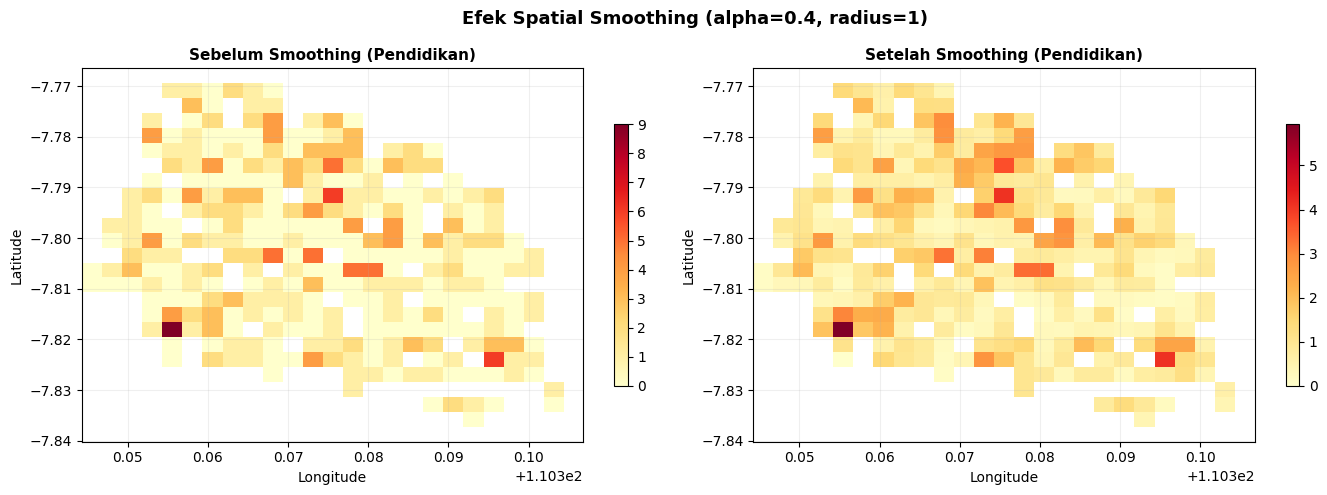

💾 outputs/figures/06_spatial_smoothing_comparison.png tersimpan


In [11]:
# Visualisasi efek Spatial Smoothing (before vs after)
if SMOOTHING_ALPHA > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f'Efek Spatial Smoothing (alpha={SMOOTHING_ALPHA}, radius={SMOOTHING_RADIUS})',
                 fontsize=13, fontweight='bold')

    # Pilih fitur total untuk visualisasi
    feat_idx = feature_cols.index('n_pendidikan') if 'n_pendidikan' in feature_cols else 0
    feat_name = feature_cols[feat_idx].replace('n_','').capitalize()

    for ax_idx, (data, title) in enumerate([
        (X_raw[:, feat_idx],        f'Sebelum Smoothing ({feat_name})'),
        (X_smooth_raw[:, feat_idx], f'Setelah Smoothing ({feat_name})'),
    ]):
        ax = axes[ax_idx]
        # Buat grid visual
        grid_vis = np.full((GRID_SIZE, GRID_SIZE), np.nan)
        for idx_z, row_z in df_grid.iterrows():
            if idx_z < len(data):
                grid_vis[int(row_z['grid_row']), int(row_z['grid_col'])] = data[idx_z]

        im = ax.imshow(grid_vis, cmap='YlOrRd', aspect='auto',
                       extent=[LON_MIN, LON_MAX, LAT_MIN, LAT_MAX],
                       origin='lower', interpolation='nearest')
        plt.colorbar(im, ax=ax, shrink=0.7)
        ax.set_title(title, fontsize=11, fontweight='bold')
        ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
        ax.grid(True, alpha=0.2)

    plt.tight_layout()
    # plt.savefig('outputs/figures/06_spatial_smoothing_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('💾 outputs/figures/06_spatial_smoothing_comparison.png tersimpan')
else:
    print('Smoothing tidak aktif — tidak ada visualisasi perbandingan.')


---
## Langkah 4: K-Means dari Scratch
---

In [12]:
# ============================================================
# K-MEANS CLUSTERING — Implementasi dari Scratch
# ============================================================
class KMeansFromScratch:
    """
    K-Means Clustering diimplementasikan dari scratch menggunakan NumPy.
    Tidak menggunakan scikit-learn atau library ML lainnya.

    Fitur:
    - Inisialisasi K-Means++ (menghindari centroid yang berdekatan)
    - Multiple random restarts (n_init)
    - Konvergensi berdasarkan pergeseran centroid
    - Penanganan klaster kosong
    """
    def __init__(self, n_clusters=3, max_iter=300, tol=1e-5, n_init=10, init='kmeans++'):
        self.n_clusters = n_clusters
        self.max_iter   = max_iter
        self.tol        = tol
        self.n_init     = n_init
        self.init       = init
        self.centroids_ = None
        self.labels_    = None
        self.inertia_   = None
        self.n_iter_    = None

    def _euclidean_distances(self, X, centroids):
        """
        Hitung jarak Euclidean (X: nxf) ke setiap centroid (kxf).
        Menggunakan broadcasting NumPy — vektorisasi penuh, tanpa loop.
        Output shape: (n, k)
        """
        diff = X[:, np.newaxis, :] - centroids[np.newaxis, :, :]  # (n, k, f)
        return np.sqrt(np.sum(diff ** 2, axis=2))                  # (n, k)

    def _init_kmeanspp(self, X):
        """
        K-Means++ initialization:
        Setiap centroid baru dipilih dengan probabilitas ∝ D²
        (jarak kuadrat ke centroid terdekat yang sudah dipilih).
        Ini memastikan centroid awal tersebar, bukan menumpuk di satu area.
        """
        idx = np.random.randint(0, X.shape[0])
        centroids = [X[idx].copy()]

        for _ in range(1, self.n_clusters):
            dists   = self._euclidean_distances(X, np.array(centroids))
            min_d   = np.min(dists, axis=1)          # jarak minimum tiap titik
            probs   = min_d ** 2
            probs  /= probs.sum()                    # normalisasi jadi distribusi
            idx     = np.random.choice(X.shape[0], p=probs)
            centroids.append(X[idx].copy())

        return np.array(centroids)

    def _run_once(self, X):
        """Satu run K-Means dari inisialisasi hingga konvergensi."""
        # Inisialisasi centroid
        if self.init == 'kmeans++':
            centroids = self._init_kmeanspp(X)
        else:
            idx = np.random.choice(X.shape[0], self.n_clusters, replace=False)
            centroids = X[idx].copy()

        labels = np.zeros(X.shape[0], dtype=int)

        for it in range(self.max_iter):
            # E-step: assignment setiap titik ke centroid terdekat
            new_labels = np.argmin(self._euclidean_distances(X, centroids), axis=1)

            # M-step: update centroid sebagai rata-rata anggota
            new_centroids = np.zeros_like(centroids)
            for k in range(self.n_clusters):
                members = X[new_labels == k]
                if len(members) > 0:
                    new_centroids[k] = members.mean(axis=0)
                else:
                    # Klaster kosong: reinisialisasi ke titik acak
                    new_centroids[k] = X[np.random.randint(0, X.shape[0])]

            # Cek konvergensi: apakah centroid sudah stabil?
            shift = np.sqrt(np.sum((new_centroids - centroids) ** 2))
            centroids = new_centroids
            labels    = new_labels

            if shift < self.tol:
                break

        # Hitung inertia: total within-cluster sum of squares
        inertia = sum(
            np.sum((X[labels == k] - centroids[k]) ** 2)
            for k in range(self.n_clusters)
            if (labels == k).any()
        )
        return centroids, labels, inertia, it + 1

    def fit(self, X):
        """Jalankan n_init kali, simpan hasil dengan inertia terkecil."""
        best = (None, None, np.inf, None)
        for _ in range(self.n_init):
            result = self._run_once(X)
            if result[2] < best[2]:
                best = result
        self.centroids_, self.labels_, self.inertia_, self.n_iter_ = best
        return self

    def predict(self, X):
        distances = self._euclidean_distances(X, self.centroids_)
        return np.argmin(distances, axis=1)


print('✅ Class KMeansFromScratch siap!')

✅ Class KMeansFromScratch siap!


In [13]:
def silhouette_score_manual(X, labels):
    """
    Silhouette Score manual — dengan guard singleton cluster.
    Singleton (klaster 1 anggota) di-skip karena a(i)=0 → s(i)=1.0 palsu.
    """
    unique_labels = np.unique(labels)
    if len(unique_labels) < 2:
        return 0.0
    cluster_sizes = {k: int(np.sum(labels == k)) for k in unique_labels}
    s_vals = []
    for i in range(X.shape[0]):
        li = labels[i]
        if cluster_sizes[li] <= 1:   # skip singleton
            continue
        same_mask = (labels == li); same_mask[i] = False
        a_i = np.mean(np.sqrt(np.sum((X[i] - X[same_mask]) ** 2, axis=1)))
        b_i = np.inf
        for ol in unique_labels:
            if ol == li: continue
            mean_d = np.mean(np.sqrt(np.sum((X[i] - X[labels==ol]) ** 2, axis=1)))
            b_i = min(b_i, mean_d)
        denom = max(a_i, b_i)
        s_vals.append((b_i - a_i) / denom if denom > 0 else 0.0)
    return float(np.mean(s_vals)) if s_vals else 0.0

print('silhouette_score_manual siap (dengan guard singleton).')


silhouette_score_manual siap (dengan guard singleton).


In [14]:
# ============================================================
# ELBOW METHOD + SILHOUETTE SCORE
# ============================================================
n_samples = len(df_grid)
K_MAX_AUTO = min(K_MAX_OVERRIDE, n_samples // 10, 10)
k_range = range(2, K_MAX_AUTO + 1)

print(f'Jumlah zona (titik data) : {n_samples}')
print(f'K yang diuji             : 2 hingga {K_MAX_AUTO}')
if n_samples < 100:
    print(f'WARNING: hanya {n_samples} zona — pertimbangkan naikkan GRID_SIZE')
print()

np.random.seed(42)
inertias    = []
sil_scores  = []

for k in k_range:
    km = KMeansFromScratch(n_clusters=k, max_iter=200, n_init=5, init='kmeans++')
    km.fit(X_for_clustering)
    inertias.append(km.inertia_)
    sil = silhouette_score_manual(X_for_clustering, km.labels_)
    sil_scores.append(sil)

    sizes = sorted([int(np.sum(km.labels_==ki)) for ki in range(k)])
    singleton = sum(1 for s in sizes if s <= 1)
    flag = f'  <-- SINGLETON x{singleton}!' if singleton else ''
    print(f'  K={k:2d}: Inertia={km.inertia_:7.2f} | Sil={sil:.4f} | distribusi={sizes}{flag}')

k_list   = list(k_range)
OPTIMAL_K = k_list[np.argmax(sil_scores)]
print(f'\nK optimal = {OPTIMAL_K} (silhouette: {max(sil_scores):.4f})')


Jumlah zona (titik data) : 305
K yang diuji             : 2 hingga 6

  K= 2: Inertia=1336.46 | Sil=0.3169 | distribusi=[104, 201]
  K= 3: Inertia=1152.56 | Sil=0.2347 | distribusi=[30, 127, 148]
  K= 4: Inertia= 985.16 | Sil=0.2728 | distribusi=[13, 53, 82, 157]
  K= 5: Inertia= 883.95 | Sil=0.2588 | distribusi=[11, 42, 50, 74, 128]
  K= 6: Inertia= 788.12 | Sil=0.2520 | distribusi=[7, 10, 41, 58, 58, 131]

K optimal = 2 (silhouette: 0.3169)


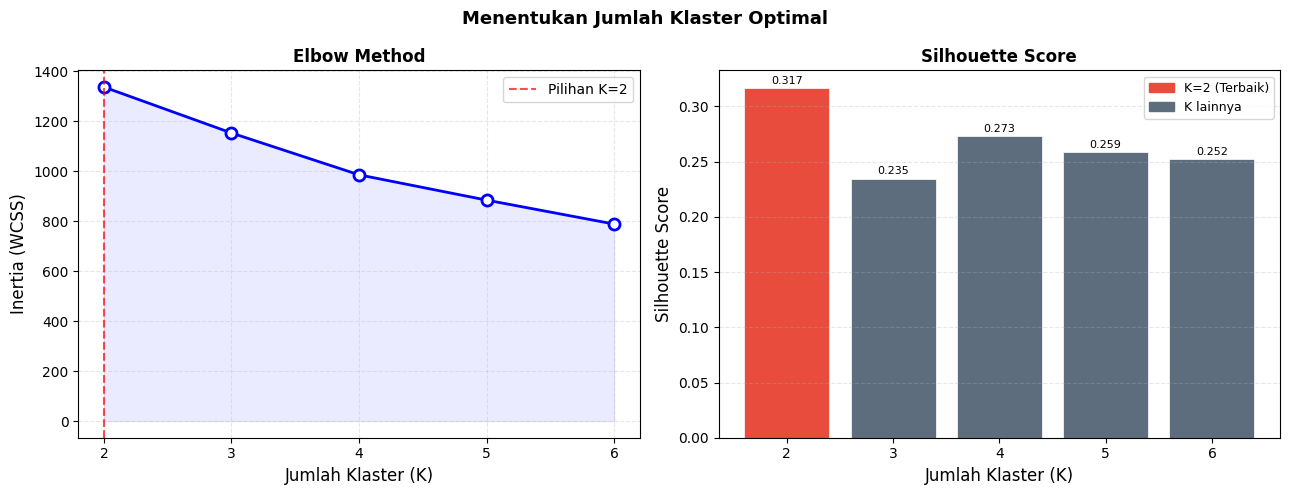

💾 outputs/figures/02_elbow_silhouette.png tersimpan


In [15]:
# Plot Elbow + Silhouette
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Menentukan Jumlah Klaster Optimal', fontsize=13, fontweight='bold')

ax1.plot(k_list, inertias, 'bo-', lw=2, ms=8, mfc='white', mew=2)
ax1.fill_between(k_list, inertias, alpha=0.08, color='blue')
ax1.axvline(x=OPTIMAL_K, color='red', ls='--', alpha=0.7, label=f'Pilihan K={OPTIMAL_K}')
ax1.set_xlabel('Jumlah Klaster (K)', fontsize=12)
ax1.set_ylabel('Inertia (WCSS)', fontsize=12)
ax1.set_title('Elbow Method', fontsize=12, fontweight='bold')
ax1.legend(fontsize=10); ax1.grid(True, alpha=0.3, ls='--'); ax1.set_xticks(k_list)

bar_colors = ['#E74C3C' if k == OPTIMAL_K else '#5D6D7E' for k in k_list]
ax2.bar(k_list, sil_scores, color=bar_colors, edgecolor='white', lw=0.5)
for k, v in zip(k_list, sil_scores):
    ax2.text(k, v + 0.002, f'{v:.3f}', ha='center', va='bottom', fontsize=8)
ax2.set_xlabel('Jumlah Klaster (K)', fontsize=12)
ax2.set_ylabel('Silhouette Score', fontsize=12)
ax2.set_title('Silhouette Score', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='y', ls='--'); ax2.set_xticks(k_list)
ax2.legend([
    mpatches.Patch(color='#E74C3C'), mpatches.Patch(color='#5D6D7E')
], [f'K={OPTIMAL_K} (Terbaik)', 'K lainnya'], fontsize=9)

plt.tight_layout()
# plt.savefig('outputs/figures/02_elbow_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 outputs/figures/02_elbow_silhouette.png tersimpan')

In [16]:
# ============================================================
# TRAINING MODEL FINAL
# ============================================================
print(f'🏋️  Training K-Means final (K={OPTIMAL_K}, 20 restarts)...')

np.random.seed(42)
km_final = KMeansFromScratch(
    n_clusters=OPTIMAL_K,
    max_iter=300,
    n_init=20,
    init='kmeans++',
    tol=1e-5
)
km_final.fit(X_for_clustering)
df_grid['cluster'] = km_final.labels_

final_sil = silhouette_score_manual(X_for_clustering, km_final.labels_)
centroids_orig = active_scaler.inverse_transform(km_final.centroids_)

print(f'\n✅ Training selesai!')
print(f'   Inertia         : {km_final.inertia_:.4f}')
print(f'   Iterasi         : {km_final.n_iter_}')
print(f'   Silhouette Score: {final_sil:.4f}')

# Urutkan klaster berdasarkan total fasilitas 5 kategori POI (tanpa menjumlahkan diversity_index)
n_poi = len(poi_cols)
total_per_k = {k: centroids_orig[k, :n_poi].sum() for k in range(OPTIMAL_K)}
sorted_clusters = sorted(total_per_k, key=total_per_k.get, reverse=True)

label_templates = [
    ('Kota 15 Menit (Ideal)', '#27AE60'),
    ('Area Pemukiman Standar', '#F39C12'),
    ('Gurun Fasilitas', '#E74C3C'),
    ('Area Transisi', '#7F8C8D'),
    ('Zona Berkembang', '#3498DB'),
    ('Zona Pinggiran', '#9B59B6'),
]
cluster_names  = {k: label_templates[rank % len(label_templates)][0] for rank, k in enumerate(sorted_clusters)}
cluster_colors = {k: label_templates[rank % len(label_templates)][1] for rank, k in enumerate(sorted_clusters)}

df_grid['cluster_label'] = df_grid['cluster'].map(cluster_names)
df_grid['cluster_color'] = df_grid['cluster'].map(cluster_colors)

print(f'\n📊 Distribusi zona per klaster:')
for k in sorted_clusters:
    mask = df_grid['cluster'] == k
    n = mask.sum()
    pct = n / len(df_grid) * 100
    raw_avg_total = df_grid.loc[mask, 'total_fasilitas'].mean()
    print(f'   Klaster {k} [{cluster_names[k]:25s}]: {n:3d} zona ({pct:.1f}%) | avg fasilitas (centroid) = {total_per_k[k]:.1f} (aktual = {raw_avg_total:.1f})')

🏋️  Training K-Means final (K=2, 20 restarts)...

✅ Training selesai!
   Inertia         : 1336.4624
   Iterasi         : 7
   Silhouette Score: 0.3169

📊 Distribusi zona per klaster:
   Klaster 0 [Kota 15 Menit (Ideal)    ]: 104 zona (34.1%) | avg fasilitas (centroid) = 5.8 (aktual = 6.7)
   Klaster 1 [Area Pemukiman Standar   ]: 201 zona (65.9%) | avg fasilitas (centroid) = 2.5 (aktual = 2.0)


---
## 🔍 Langkah 5: Profiling & Diagnosis Klaster

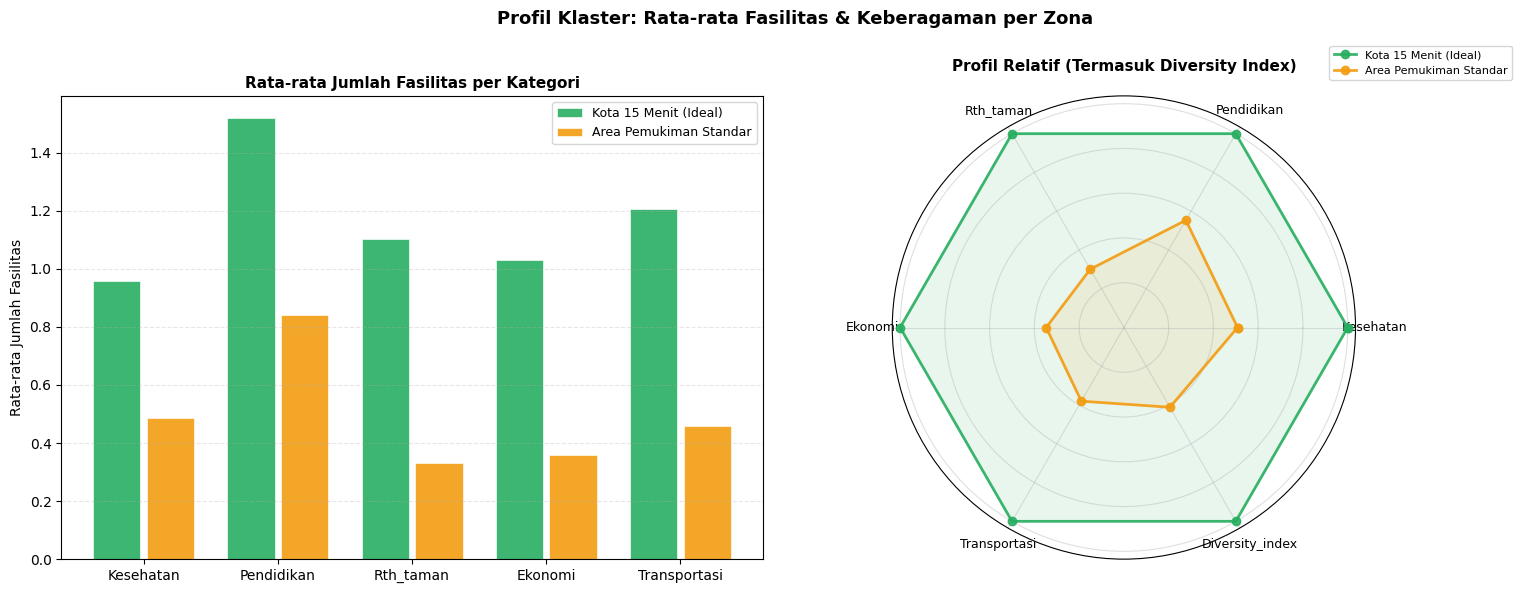

💾 outputs/figures/03_cluster_profiles.png tersimpan


In [17]:
# Visualisasi profil klaster: bar chart (5 kategori fasilitas) + radar (6 fitur termasuk Diversity Index)
poi_labels     = [c.replace('n_', '').capitalize() for c in poi_cols]
feature_labels = [c.replace('n_', '').capitalize() for c in feature_cols]
n_poi  = len(poi_cols)
n_feat = len(feature_cols)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Profil Klaster: Rata-rata Fasilitas & Keberagaman per Zona', fontsize=13, fontweight='bold')

# Bar chart (hanya 5 kategori jumlah fasilitas agar skala sumbu Y konsisten)
ax = axes[0]
x = np.arange(n_poi)
bw = 0.8 / OPTIMAL_K
offsets = np.linspace(-(OPTIMAL_K-1)/2*bw, (OPTIMAL_K-1)/2*bw, OPTIMAL_K)
for idx, k in enumerate(sorted_clusters):
    vals = [centroids_orig[k, i] for i in range(n_poi)]
    ax.bar(x + offsets[idx], vals, bw * 0.88,
           label=cluster_names[k], color=cluster_colors[k],
           edgecolor='white', lw=0.5, alpha=0.9)
ax.set_xticks(x); ax.set_xticklabels(poi_labels, fontsize=10)
ax.set_ylabel('Rata-rata Jumlah Fasilitas', fontsize=10)
ax.set_title('Rata-rata Jumlah Fasilitas per Kategori', fontsize=11, fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis='y', ls='--')

# Radar chart (hapus axes[1] Cartesian terlebih dahulu agar tidak menumpuk di belakang polar plot)
axes[1].remove()
ax2 = fig.add_subplot(1, 2, 2, polar=True)
angles = np.linspace(0, 2*np.pi, n_feat, endpoint=False).tolist() + [0]
max_v = [max(centroids_orig[:, i].max(), 1e-6) for i in range(n_feat)]
for k in sorted_clusters:
    vn = [centroids_orig[k, i] / max_v[i] for i in range(n_feat)] + [centroids_orig[k, 0] / max_v[0]]
    ax2.plot(angles, vn, 'o-', lw=2, color=cluster_colors[k], alpha=0.9, label=cluster_names[k])
    ax2.fill(angles, vn, alpha=0.1, color=cluster_colors[k])
ax2.set_xticks(angles[:-1]); ax2.set_xticklabels(feature_labels, fontsize=9)
ax2.set_yticklabels([]); ax2.set_title('Profil Relatif (Termasuk Diversity Index)', fontsize=11, fontweight='bold', pad=18)
ax2.grid(True, alpha=0.4)
ax2.legend(fontsize=8, loc='upper right', bbox_to_anchor=(1.35, 1.12))

plt.tight_layout()
# plt.savefig('outputs/figures/03_cluster_profiles.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 outputs/figures/03_cluster_profiles.png tersimpan')

In [18]:
# Laporan diagnosa teks
poi_labels = [c.replace('n_', '').capitalize() for c in poi_cols]
n_poi = len(poi_cols)

print('=' * 65)
print(f'  LAPORAN DIAGNOSA TATA RUANG — {PLACE_NAME}')
print('=' * 65)

for k in sorted_clusters:
    mask = df_grid['cluster'] == k
    sub  = df_grid[mask]
    n    = mask.sum()
    pct  = n / len(df_grid) * 100

    print(f'\n  ▶ {cluster_names[k]}')
    avg_entropy = sub["diversity_index"].mean()
    entropy_bar = '█' * int(round(avg_entropy * 10)) + '░' * (10 - int(round(avg_entropy * 10)))
    total_poi_centroid = centroids_orig[k, :n_poi].sum()
    print(f'    {n} zona ({pct:.1f}%) | Total avg fasilitas: {total_poi_centroid:.1f} | Shannon H: {entropy_bar} {avg_entropy:.3f} (0=monopoli, 1=seimbang)')
    for i, col in enumerate(poi_cols):
        avg = centroids_orig[k, i]
        bar = '█' * min(int(round(avg / 5)), 20) + '░' * max(0, 5 - int(round(avg / 5)))
        print(f'    {col.replace("n_","").capitalize():15s}: {bar} {avg:.1f}')

print('\n' + '=' * 65)
print('  REKOMENDASI KEBIJAKAN')
print('=' * 65)
for k in sorted_clusters:
    label = cluster_names[k]
    print(f'\n  {label}')
    if 'Ideal' in label:
        print('  → PERTAHANKAN kualitas. Fokus pada aksesibilitas pejalan kaki & konektivitas antar-fasilitas.')
    elif 'Standar' in label:
        # Cari kategori fasilitas fisik (5 kategori POI) yang paling kurang
        min_idx = int(np.argmin([centroids_orig[k, i] for i in range(n_poi)]))
        min_cat = poi_labels[min_idx]
        min_val = centroids_orig[k, min_idx]
        print(f'  → TINGKATKAN: kategori {min_cat} paling minim (rata-rata {min_val:.1f}/zona), perlu penambahan fasilitas.')
    elif 'Gurun' in label:
        print('  → INTERVENSI MENDESAK: semua kategori fasilitas sangat minim.')
    else:
        print('  → KEMBANGKAN: potensi ada, perlu investasi bertahap.')
print()

  LAPORAN DIAGNOSA TATA RUANG — Kota Yogyakarta, Daerah Istimewa Yogyakarta, Indonesia

  ▶ Kota 15 Menit (Ideal)
    104 zona (34.1%) | Total avg fasilitas: 5.8 | Shannon H: ███████░░░ 0.664 (0=monopoli, 1=seimbang)
    Kesehatan      : ░░░░░ 1.0
    Pendidikan     : ░░░░░ 1.5
    Rth_taman      : ░░░░░ 1.1
    Ekonomi        : ░░░░░ 1.0
    Transportasi   : ░░░░░ 1.2

  ▶ Area Pemukiman Standar
    201 zona (65.9%) | Total avg fasilitas: 2.5 | Shannon H: ██░░░░░░░░ 0.174 (0=monopoli, 1=seimbang)
    Kesehatan      : ░░░░░ 0.5
    Pendidikan     : ░░░░░ 0.8
    Rth_taman      : ░░░░░ 0.3
    Ekonomi        : ░░░░░ 0.4
    Transportasi   : ░░░░░ 0.5

  REKOMENDASI KEBIJAKAN

  Kota 15 Menit (Ideal)
  → PERTAHANKAN kualitas. Fokus pada aksesibilitas pejalan kaki & konektivitas antar-fasilitas.

  Area Pemukiman Standar
  → TINGKATKAN: kategori Rth_taman paling minim (rata-rata 0.3/zona), perlu penambahan fasilitas.



---
## 🗺️ Langkah 6: Visualisasi Peta

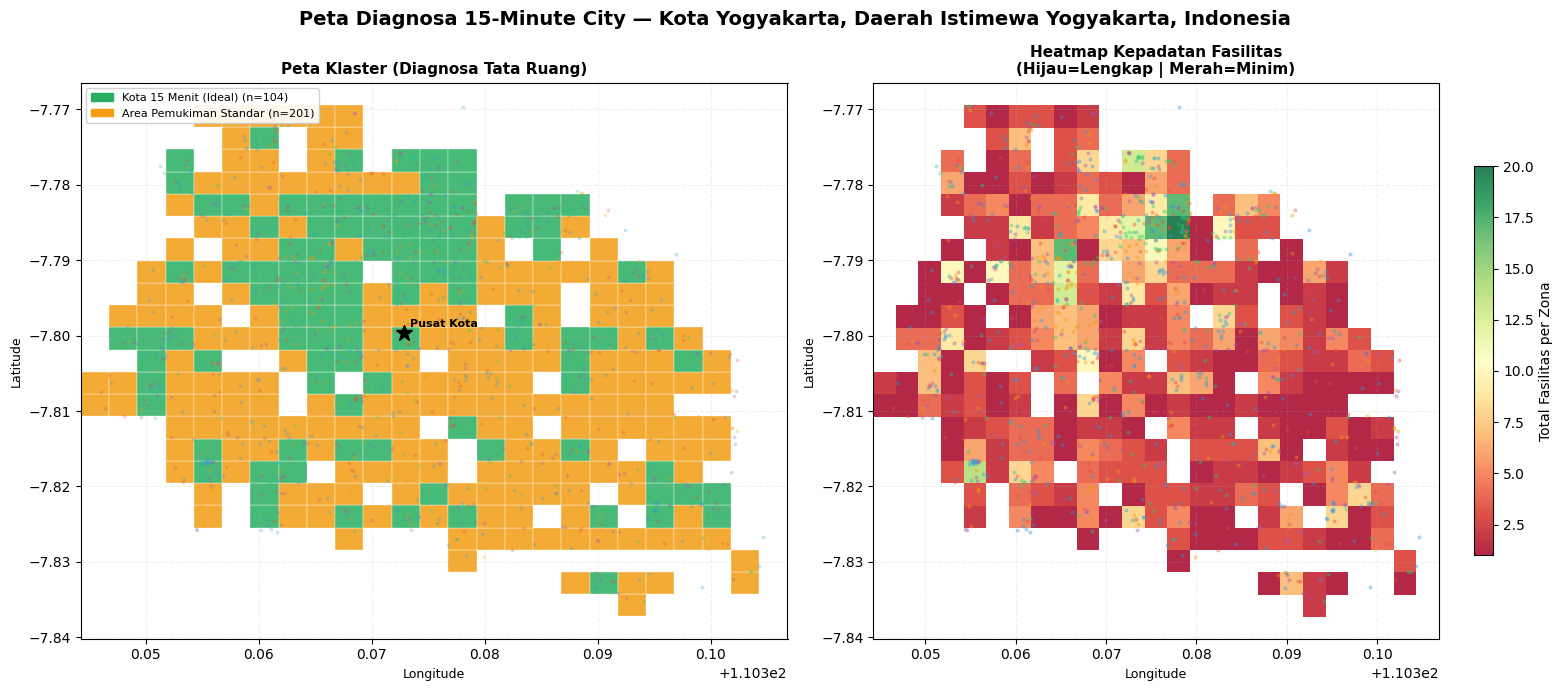

💾 outputs/figures/04_peta_choropleth.png tersimpan


In [19]:
# Choropleth Map — Matplotlib
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle(f'Peta Diagnosa 15-Minute City — {PLACE_NAME}', fontsize=14, fontweight='bold')

# Peta klaster
ax1 = axes[0]
for _, row in df_grid.iterrows():
    ax1.add_patch(plt.Rectangle(
        (row['lon_min'], row['lat_min']),
        row['lon_max']-row['lon_min'], row['lat_max']-row['lat_min'],
        lw=0.3, ec='white', fc=row['cluster_color'], alpha=0.85
    ))
for kat, df_p in poi_data.items():
    if len(df_p) > 0:
        ax1.scatter(df_p['lon'], df_p['lat'], c=poi_colors[kat], s=3, alpha=0.2, zorder=5)
ax1.set_xlim(LON_MIN, LON_MAX); ax1.set_ylim(LAT_MIN, LAT_MAX)
ax1.set_xlabel('Longitude', fontsize=9); ax1.set_ylabel('Latitude', fontsize=9)
ax1.set_title('Peta Klaster (Diagnosa Tata Ruang)', fontsize=11, fontweight='bold')
legend_patches = [mpatches.Patch(color=cluster_colors[k],
                  label=f"{cluster_names[k]} (n={(df_grid['cluster']==k).sum()})")
                  for k in sorted_clusters]
ax1.legend(handles=legend_patches, fontsize=8, loc='upper left', framealpha=0.9)
ax1.plot(CENTER_LON, CENTER_LAT, 'k*', ms=12, zorder=10)
ax1.annotate('Pusat Kota', (CENTER_LON, CENTER_LAT), xytext=(4,4),
             textcoords='offset points', fontsize=8, fontweight='bold')
ax1.grid(True, alpha=0.2, ls='--')

# Heatmap total fasilitas (gunakan np.nan untuk sel di luar zona aktif agar area laut tidak berwarna merah)
ax2 = axes[1]
grid_total = np.full((GRID_SIZE, GRID_SIZE), np.nan)
for _, row in df_grid.iterrows():
    grid_total[int(row['grid_row']), int(row['grid_col'])] = row['total_fasilitas']
im = ax2.imshow(grid_total, cmap='RdYlGn', aspect='auto',
                extent=[LON_MIN, LON_MAX, LAT_MIN, LAT_MAX],
                origin='lower', alpha=0.85, interpolation='nearest')
for kat, df_p in poi_data.items():
    if len(df_p) > 0:
        ax2.scatter(df_p['lon'], df_p['lat'], c=poi_colors[kat], s=4, alpha=0.3, zorder=5)
plt.colorbar(im, ax=ax2, shrink=0.7, label='Total Fasilitas per Zona')
ax2.set_xlim(LON_MIN, LON_MAX); ax2.set_ylim(LAT_MIN, LAT_MAX)
ax2.set_xlabel('Longitude', fontsize=9); ax2.set_ylabel('Latitude', fontsize=9)
ax2.set_title('Heatmap Kepadatan Fasilitas\n(Hijau=Lengkap | Merah=Minim)', fontsize=11, fontweight='bold')
ax2.grid(True, alpha=0.2, ls='--')

plt.tight_layout()
# plt.savefig('outputs/figures/04_peta_choropleth.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 outputs/figures/04_peta_choropleth.png tersimpan')

In [20]:
# ============================================================
# PETA INTERAKTIF dengan Folium
# ============================================================
m = folium.Map(location=[CENTER_LAT, CENTER_LON], zoom_start=13,
               tiles='CartoDB positron')

# Layer klaster
cluster_layer = folium.FeatureGroup(name='🏙️ Klaster Zona', show=True)
for _, row in df_grid.iterrows():
    tooltip_html = f"""
    <b>📍 Zona {row['zona_id']}</b><br>
    <hr style='margin:3px 0'>
    🏥 Kesehatan  : {row['n_kesehatan']}<br>
    🎓 Pendidikan : {row['n_pendidikan']}<br>
    🌳 RTH/Taman  : {row['n_rth_taman']}<br>
    🛒 Ekonomi    : {row['n_ekonomi']}<br>
    🚌 Transportasi: {row['n_transportasi']}<br>
    <hr style='margin:3px 0'>
    📊 Total: <b>{row['total_fasilitas']}</b> | Shannon H: {row['diversity_index']:.3f} {'▓'*int(row['diversity_index']*10)}{'░'*(10-int(row['diversity_index']*10))}<br>
    <span style='color:{row["cluster_color"]};font-weight:bold'>{row['cluster_label']}</span>
    """
    folium.Rectangle(
        bounds=[[row['lat_min'], row['lon_min']], [row['lat_max'], row['lon_max']]],
        color='white', weight=0.5, fill=True,
        fill_color=row['cluster_color'], fill_opacity=0.6,
        tooltip=folium.Tooltip(tooltip_html)
    ).add_to(cluster_layer)
cluster_layer.add_to(m)

# Layer POI per kategori
for kat, df_p in poi_data.items():
    if len(df_p) == 0:
        continue
    poi_layer = folium.FeatureGroup(name=f'{poi_icons[kat]} POI: {kat.capitalize()}', show=False)
    for _, poi_row in df_p.iterrows():
        folium.CircleMarker(
            location=[poi_row['lat'], poi_row['lon']],
            radius=4,
            color=poi_colors[kat], fill=True, fill_opacity=0.7,
            tooltip=str(poi_row.get('nama_poi', kat))
        ).add_to(poi_layer)
    poi_layer.add_to(m)

# Legend HTML
legend_items = ''.join([
    f"<span style='background:{cluster_colors[k]};padding:2px 10px;"
    f"border-radius:3px;opacity:0.85'>&nbsp;</span> {cluster_names[k]}<br>"
    for k in sorted_clusters
])
legend_html = f"""
<div style='position:fixed;bottom:30px;left:30px;z-index:1000;
     background:white;padding:14px;border-radius:8px;
     border:1px solid #ccc;font-family:Arial;font-size:12px;
     box-shadow:2px 2px 6px rgba(0,0,0,.15)'>
<b>🏙️ Diagnosa 15-Minute City</b><br>
<b>{PLACE_NAME}</b><br><br>
{legend_items}
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))
folium.LayerControl(collapsed=False).add_to(m)

if SAVE_HTML_MAP:
    m.save('outputs/maps/05_peta_interaktif.html')
    print('✅ Peta interaktif tersimpan: outputs/maps/05_peta_interaktif.html')
    print('   Buka file HTML di browser untuk eksplorasi interaktif!')

m  # Tampilkan inline di Jupyter

In [21]:
# Simpan hasil akhir ke CSV
output_cols = ['zona_id', 'lat_center', 'lon_center'] + feature_cols + \
              ['total_fasilitas',  'cluster', 'cluster_label']
# df_grid[output_cols].to_csv('data/processed/hasil_analisis_15min_city.csv', index=False)
print('✅ Analisis selesai.')
print(f'   {len(df_grid)} zona | {OPTIMAL_K} klaster | {total} total POI')
df_grid[output_cols].head(10)

✅ Analisis selesai.
   305 zona | 2 klaster | 1131 total POI


,zona_id,lat_center,lon_center,n_kesehatan,n_pendidikan,n_rth_taman,n_ekonomi,n_transportasi,diversity_index,total_fasilitas,cluster,cluster_label
0,Z01-19,-7.835756,110.393036,0,0,1,0,1,0.430677,2,1,Area Pemukiman Standar
1,Z02-17,-7.832809,110.388033,0,0,0,1,0,0.000000,1,1,Area Pemukiman Standar
2,Z02-18,-7.832809,110.390535,2,2,0,1,2,0.839911,7,0,Kota 15 Menit (Ideal)
3,Z02-19,-7.832809,110.393036,0,1,0,0,1,0.430677,2,1,Area Pemukiman Standar
4,Z02-20,-7.832809,110.395537,0,0,1,0,0,0.000000,1,1,Area Pemukiman Standar
5,Z02-23,-7.832809,110.403041,1,0,0,0,0,0.000000,1,1,Area Pemukiman Standar
6,Z03-13,-7.829861,110.378028,0,1,0,0,0,0.000000,1,1,Area Pemukiman Standar
7,Z03-23,-7.829861,110.403041,0,1,2,0,0,0.395488,3,1,Area Pemukiman Standar
8,Z04-09,-7.826914,110.368023,0,0,1,0,0,0.000000,1,1,Area Pemukiman Standar
9,Z04-13,-7.826914,110.378028,1,1,1,0,0,0.682606,3,1,Area Pemukiman Standar


---
## 📊 Langkah 7: Analisis Persentase 15-Minute City per Sub-Wilayah

Hitung berapa persen luas setiap sub-wilayah (kota/kabupaten, kecamatan, dll)
yang sudah termasuk klaster **15-Minute City**.

**Cara kerja:**
- Ambil polygon sub-wilayah dari OSM (admin_level yang dipilih)
- Untuk setiap sel grid, hitung overlap luasnya dengan setiap sub-wilayah
- Persentase = luas grid 'ideal' di dalam sub-wilayah / total luas sub-wilayah × 100


In [22]:
# ============================================================
# KONFIGURASI ANALISIS SUB-WILAYAH
# ============================================================

# Level admin OSM untuk sub-wilayah:
# 5 = kota/kabupaten (misal: Jakarta Utara, Jakarta Selatan)
# 6 = kecamatan
# 7 = kelurahan
SUB_WILAYAH_LEVEL = 5

# Label klaster yang dianggap '15-Minute City'
# Sesuaikan dengan label yang muncul di output model kamu
LABEL_IDEAL = 'Kota 15 Menit (Ideal)'

# Minimum overlap (%) antara sel grid dan sub-wilayah agar dihitung
# (menghindari sel di perbatasan dihitung dobel)
MIN_OVERLAP_PCT = 10.0

print(f'Sub-wilayah level : {SUB_WILAYAH_LEVEL}')
print(f'Label ideal       : {LABEL_IDEAL}')
print(f'Min overlap       : {MIN_OVERLAP_PCT}%')
print()
print('Klaster yang ada di model saat ini:')
for k in sorted_clusters:
    n = (df_grid['cluster'] == k).sum()
    print(f'  {cluster_names[k]:30s}: {n} zona')


Sub-wilayah level : 5
Label ideal       : Kota 15 Menit (Ideal)
Min overlap       : 10.0%

Klaster yang ada di model saat ini:
  Kota 15 Menit (Ideal)         : 104 zona
  Area Pemukiman Standar        : 201 zona


In [23]:
# ============================================================
# AMBIL POLYGON SUB-WILAYAH DARI OSM
# ============================================================
from shapely.geometry import box as shapely_box
import geopandas as gpd


def ambil_sub_wilayah(boundary_polygon, place_name, admin_level):
    """
    Ambil polygon sub-wilayah administratif dari OSM.

    Masalah OSM Indonesia:
    Query admin_level=5 sering mengembalikan campuran level administratif
    (kota, kecamatan, kelurahan, bahkan RT/RW) karena tagging tidak konsisten.

    Solusi — 4 lapis filter:
    1. Hanya Polygon/MultiPolygon
    2. Centroid di dalam batas kota
    3. Filter luas MINIMUM — buang polygon terlalu kecil (RT/RW/Dusun)
    4. Filter luas MAKSIMUM — buang polygon terlalu besar (duplikat kota)
    5. Filter nama — buang yang mengandung kata RT/RW/Dusun/Gang
    """
    print(f'Mengambil sub-wilayah admin_level={admin_level} untuk {place_name}...')

    try:
        gdf_raw = ox.features_from_polygon(
            boundary_polygon,
            tags={'boundary': 'administrative', 'admin_level': str(admin_level)}
        )
    except Exception as e:
        print(f'  Gagal: {e}')
        print('  Coba ubah SUB_WILAYAH_LEVEL')
        return None

    kota_area = boundary_polygon.area

    # Filter 1: hanya Polygon/MultiPolygon
    gdf = gdf_raw[gdf_raw.geometry.geom_type.isin(['Polygon','MultiPolygon'])].copy()
    print(f'  Raw polygon         : {len(gdf)}')

    # Filter 2: centroid di dalam batas kota
    gdf['_centroid'] = gdf.geometry.centroid
    gdf = gdf[gdf['_centroid'].apply(boundary_polygon.contains)].copy()
    print(f'  Setelah filter kota : {len(gdf)}')

    # Filter 3: luas MINIMUM
    # Buang polygon terlalu kecil (RT/RW/Dusun)
    # Threshold: minimal 0.5% dari luas kota
    # Contoh Jakarta (~660 km²): min luas = 660 × 0.5% = 3.3 km²
    # → lolos: Jakarta Utara (~142 km²), Jakarta Pusat (~48 km²)
    # → dibuang: RT (~0.01 km²), RW (~0.05 km²), Kelurahan (~1 km²)
    MIN_LUAS_PCT = 0.70  # persen dari luas kota
    min_area     = kota_area * (MIN_LUAS_PCT / 100)
    gdf = gdf[gdf.geometry.area >= min_area].copy()
    print(f'  Setelah filter min  : {len(gdf)}  (min luas: {min_area*111**2:.1f} km²)')

    # Filter 4: luas MAKSIMUM
    # Buang polygon yang hampir sama besar dengan kota (duplikat/parent polygon)
    gdf = gdf[gdf.geometry.area < kota_area * 0.9].copy()
    print(f'  Setelah filter max  : {len(gdf)}')

    # Filter 5: nama — buang RT, RW, Dusun, Gang, dll
    name_col = next((c for c in ['name','name:id','official_name'] if c in gdf.columns), None)
    if name_col:
        gdf['nama_sub'] = gdf[name_col].fillna('')
        # Pattern nama yang harus dibuang
        buang_pattern = r'^(RT|RW|Dusun|Gang|Gg\.|Jl\.|Jalan|Blok)\s'
        mask_buang    = gdf['nama_sub'].str.match(buang_pattern, case=False, na=False)
        n_buang       = mask_buang.sum()
        if n_buang > 0:
            print(f'  Buang nama RT/RW    : {n_buang} polygon')
            gdf = gdf[~mask_buang].copy()
        gdf['nama_sub'] = gdf['nama_sub'].replace('', 'Tanpa Nama')
    else:
        gdf['nama_sub'] = [f'Sub-{i:03d}' for i in range(len(gdf))]

    print(f'  TOTAL FINAL         : {len(gdf)}')

    gdf['luas_km2'] = gdf.geometry.area * 111**2
    # Deduplikasi nama sub-wilayah (ambil polygon terluas jika ada duplikat level di OSM)
    gdf = gdf.sort_values('luas_km2', ascending=False).drop_duplicates(subset=['nama_sub'], keep='first').copy()
    gdf = gdf[['nama_sub','geometry','luas_km2']].reset_index(drop=True)
    gdf['sub_id']   = [f'S{i:03d}' for i in range(len(gdf))]

    if len(gdf) == 0:
        print('  WARNING: 0 sub-wilayah tersisa setelah filter!')
        print('  Coba turunkan MIN_LUAS_PCT atau ubah SUB_WILAYAH_LEVEL')
        return None

    return gdf


gdf_sub = ambil_sub_wilayah(
    BOUNDARY_POLYGON, PLACE_NAME, SUB_WILAYAH_LEVEL
)

if gdf_sub is not None:
    print(f'\nSub-wilayah hasil filter:')
    print(gdf_sub[['sub_id','nama_sub','luas_km2']]
          .sort_values('luas_km2', ascending=False)
          .to_string(index=False))
    print(f'\nJika ada yang tidak sesuai, ubah MIN_LUAS_PCT di dalam fungsi ambil_sub_wilayah().')


Mengambil sub-wilayah admin_level=5 untuk Kota Yogyakarta, Daerah Istimewa Yogyakarta, Indonesia...


  Raw polygon         : 108
  Setelah filter kota : 87
  Setelah filter min  : 60  (min luas: 0.2 km²)
  Setelah filter max  : 59
  TOTAL FINAL         : 59

Sub-wilayah hasil filter:
sub_id         nama_sub  luas_km2
  S000       Umbulharjo  8.263982
  S001     Gondokusuman  4.213937
  S002         Kotagede  3.203900
  S003        Tegalrejo  3.171359
  S004      Mantrijeron  2.818297
  S005       Mergangsan  2.502033
  S006       Wirobrajan  1.839142
  S007            Jetis  1.824901
  S008        Sorosutan  1.633371
  S009        Muja muju  1.625383
  S010           Kraton  1.589484
  S011         Pandeyan  1.446448
  S012         Giwangan  1.395553
  S013     Rejowinangun  1.350739
  S014           Baciro  1.106872
  S015        Danurejan  1.092872
  S016        Wirogunan  1.054235
  S017       Gondomanan  1.040466
  S018    Brontokusuman  1.025431
  S019         Prenggan  0.984479
  S020     Gedongtengen  0.931049
  S021       Gedongkiwo  0.929461
  S022 Suryodiningratan  0.907959


In [24]:
# ============================================================
# HITUNG PERSENTASE 15-MINUTE CITY PER SUB-WILAYAH
# ============================================================

def hitung_persentase_per_subwilayah(df_grid, gdf_sub, label_ideal, min_overlap_pct=10.0):
    """
    Hitung persentase luas 15-Minute City di setiap sub-wilayah.

    Algoritma:
    Untuk setiap kombinasi (sel_grid, sub_wilayah):
      - Hitung luas irisan antara sel grid dan polygon sub-wilayah
      - Jika irisan >= MIN_OVERLAP_PCT dari luas sel, masukkan ke perhitungan
      - Jika sel termasuk klaster ideal: tambahkan ke luas_ideal_km2
      - Selalu tambahkan ke luas_total_km2

    Persentase = luas_ideal / luas_total × 100
    """
    results = []
    n_sub   = len(gdf_sub)

    for sub_idx, sub_row in gdf_sub.iterrows():
        sub_geom   = sub_row.geometry
        sub_area   = sub_geom.area  # dalam satuan derajat²
        nama_sub   = sub_row['nama_sub']

        luas_ideal  = 0.0  # derajat² → km² nanti
        luas_total  = 0.0
        n_sel_ideal = 0
        n_sel_total = 0
        cluster_breakdown = {}

        for _, grid_row in df_grid.iterrows():
            # Buat polygon sel grid
            sel_box = shapely_box(
                grid_row['lon_min'], grid_row['lat_min'],
                grid_row['lon_max'], grid_row['lat_max']
            )
            sel_area = sel_box.area

            try:
                irisan      = sub_geom.intersection(sel_box)
                irisan_area = irisan.area
            except:
                continue

            # Skip jika overlap terlalu kecil
            if irisan_area / sel_area * 100 < min_overlap_pct:
                continue

            # Proporsi sel yang masuk sub-wilayah ini
            proporsi = irisan_area / sel_area
            luas_kontribusi = irisan_area * 111**2  # convert ke km²

            luas_total  += luas_kontribusi
            n_sel_total += 1

            # Catat per klaster
            klabel = grid_row['cluster_label']
            cluster_breakdown[klabel] = cluster_breakdown.get(klabel, 0) + luas_kontribusi

            # Jika klaster ideal
            if klabel == label_ideal:
                luas_ideal  += luas_kontribusi
                n_sel_ideal += 1

        pct_ideal = (luas_ideal / luas_total * 100) if luas_total > 0 else 0.0

        results.append({
            'sub_id'          : sub_row['sub_id'],
            'nama_sub'        : nama_sub,
            'luas_total_km2'  : round(luas_total, 2),
            'luas_ideal_km2'  : round(luas_ideal, 2),
            'pct_15min_city'  : round(pct_ideal, 1),
            'n_sel_ideal'     : n_sel_ideal,
            'n_sel_total'     : n_sel_total,
            'cluster_detail'  : cluster_breakdown,
        })

        pct_bar = '█' * int(pct_ideal / 5) + '░' * (20 - int(pct_ideal / 5))
        print(f'  {nama_sub:30s}: {pct_bar} {pct_ideal:5.1f}%')

    return pd.DataFrame(results)


print('Menghitung persentase 15-Minute City per sub-wilayah...')
print('='*65)
df_pct = hitung_persentase_per_subwilayah(
    df_grid, gdf_sub, LABEL_IDEAL, MIN_OVERLAP_PCT
)
print('='*65)
print(f'\nTotal sub-wilayah   : {len(df_pct)}')
print(f'Rata-rata pct ideal : {df_pct["pct_15min_city"].mean():.1f}%')
print(f'Sub-wilayah terbaik : {df_pct.loc[df_pct["pct_15min_city"].idxmax(), "nama_sub"]} ({df_pct["pct_15min_city"].max():.1f}%)')
print(f'Sub-wilayah terberat: {df_pct.loc[df_pct["pct_15min_city"].idxmin(), "nama_sub"]} ({df_pct["pct_15min_city"].min():.1f}%)')


Menghitung persentase 15-Minute City per sub-wilayah...
  Umbulharjo                    : ███░░░░░░░░░░░░░░░░░  15.8%
  Gondokusuman                  : ████████████░░░░░░░░  63.4%
  Kotagede                      : ██████░░░░░░░░░░░░░░  30.2%


  Tegalrejo                     : ████░░░░░░░░░░░░░░░░  22.7%
  Mantrijeron                   : ██████░░░░░░░░░░░░░░  32.9%
  Mergangsan                    : ████░░░░░░░░░░░░░░░░  20.9%


  Wirobrajan                    : ██████░░░░░░░░░░░░░░  34.6%
  Jetis                         : █████████░░░░░░░░░░░  48.3%
  Sorosutan                     : ██░░░░░░░░░░░░░░░░░░  12.5%
  Muja muju                     : ████░░░░░░░░░░░░░░░░  20.2%


  Kraton                        : ████░░░░░░░░░░░░░░░░  23.6%
  Pandeyan                      : █░░░░░░░░░░░░░░░░░░░   8.4%
  Giwangan                      : ███░░░░░░░░░░░░░░░░░  16.2%


  Rejowinangun                  : ██░░░░░░░░░░░░░░░░░░  10.7%
  Baciro                        : ████░░░░░░░░░░░░░░░░  22.5%
  Danurejan                     : █████████████░░░░░░░  69.6%
  Wirogunan                     : ███░░░░░░░░░░░░░░░░░  15.9%
  Gondomanan                    : █████████████░░░░░░░  67.1%


...

  Prawirodirjan                 : ██████████████░░░░░░  74.6%
  Pakualaman                    : ██░░░░░░░░░░░░░░░░░░  13.4%
  Semaki                        : ██████░░░░░░░░░░░░░░  34.3%
  Bumijo                        : ███████░░░░░░░░░░░░░  35.2%


  Bener                         : ██████████░░░░░░░░░░  54.1%
  Bausasran                     : █████████████░░░░░░░  65.3%
  Gowongan                      : ███████████████░░░░░  78.1%
  Pringgokusuman                : ████████████░░░░░░░░  61.5%
  Sosromenduran                 : ███████████████████░  97.0%


  Kadipaten                     : ░░░░░░░░░░░░░░░░░░░░   0.0%
  Keparakan                     : ██░░░░░░░░░░░░░░░░░░  10.9%
  Patehan                       : ░░░░░░░░░░░░░░░░░░░░   0.0%
  Patangpuluhan                 : ██████░░░░░░░░░░░░░░  31.1%


  Ngupasan                      : ██████████░░░░░░░░░░  51.4%
  Purwokinanti                  : ████░░░░░░░░░░░░░░░░  21.0%
  Notoprajan                    : ███████░░░░░░░░░░░░░  38.0%
  Suryatmajan                   : █████████████████░░░  89.3%


  Tegalpanggung                 : ██████████░░░░░░░░░░  54.7%
  Gunung ketur                  : ░░░░░░░░░░░░░░░░░░░░   0.0%

Total sub-wilayah   : 55
Rata-rata pct ideal : 37.8%
Sub-wilayah terbaik : Sosromenduran (97.0%)
Sub-wilayah terberat: Tahunan (0.0%)


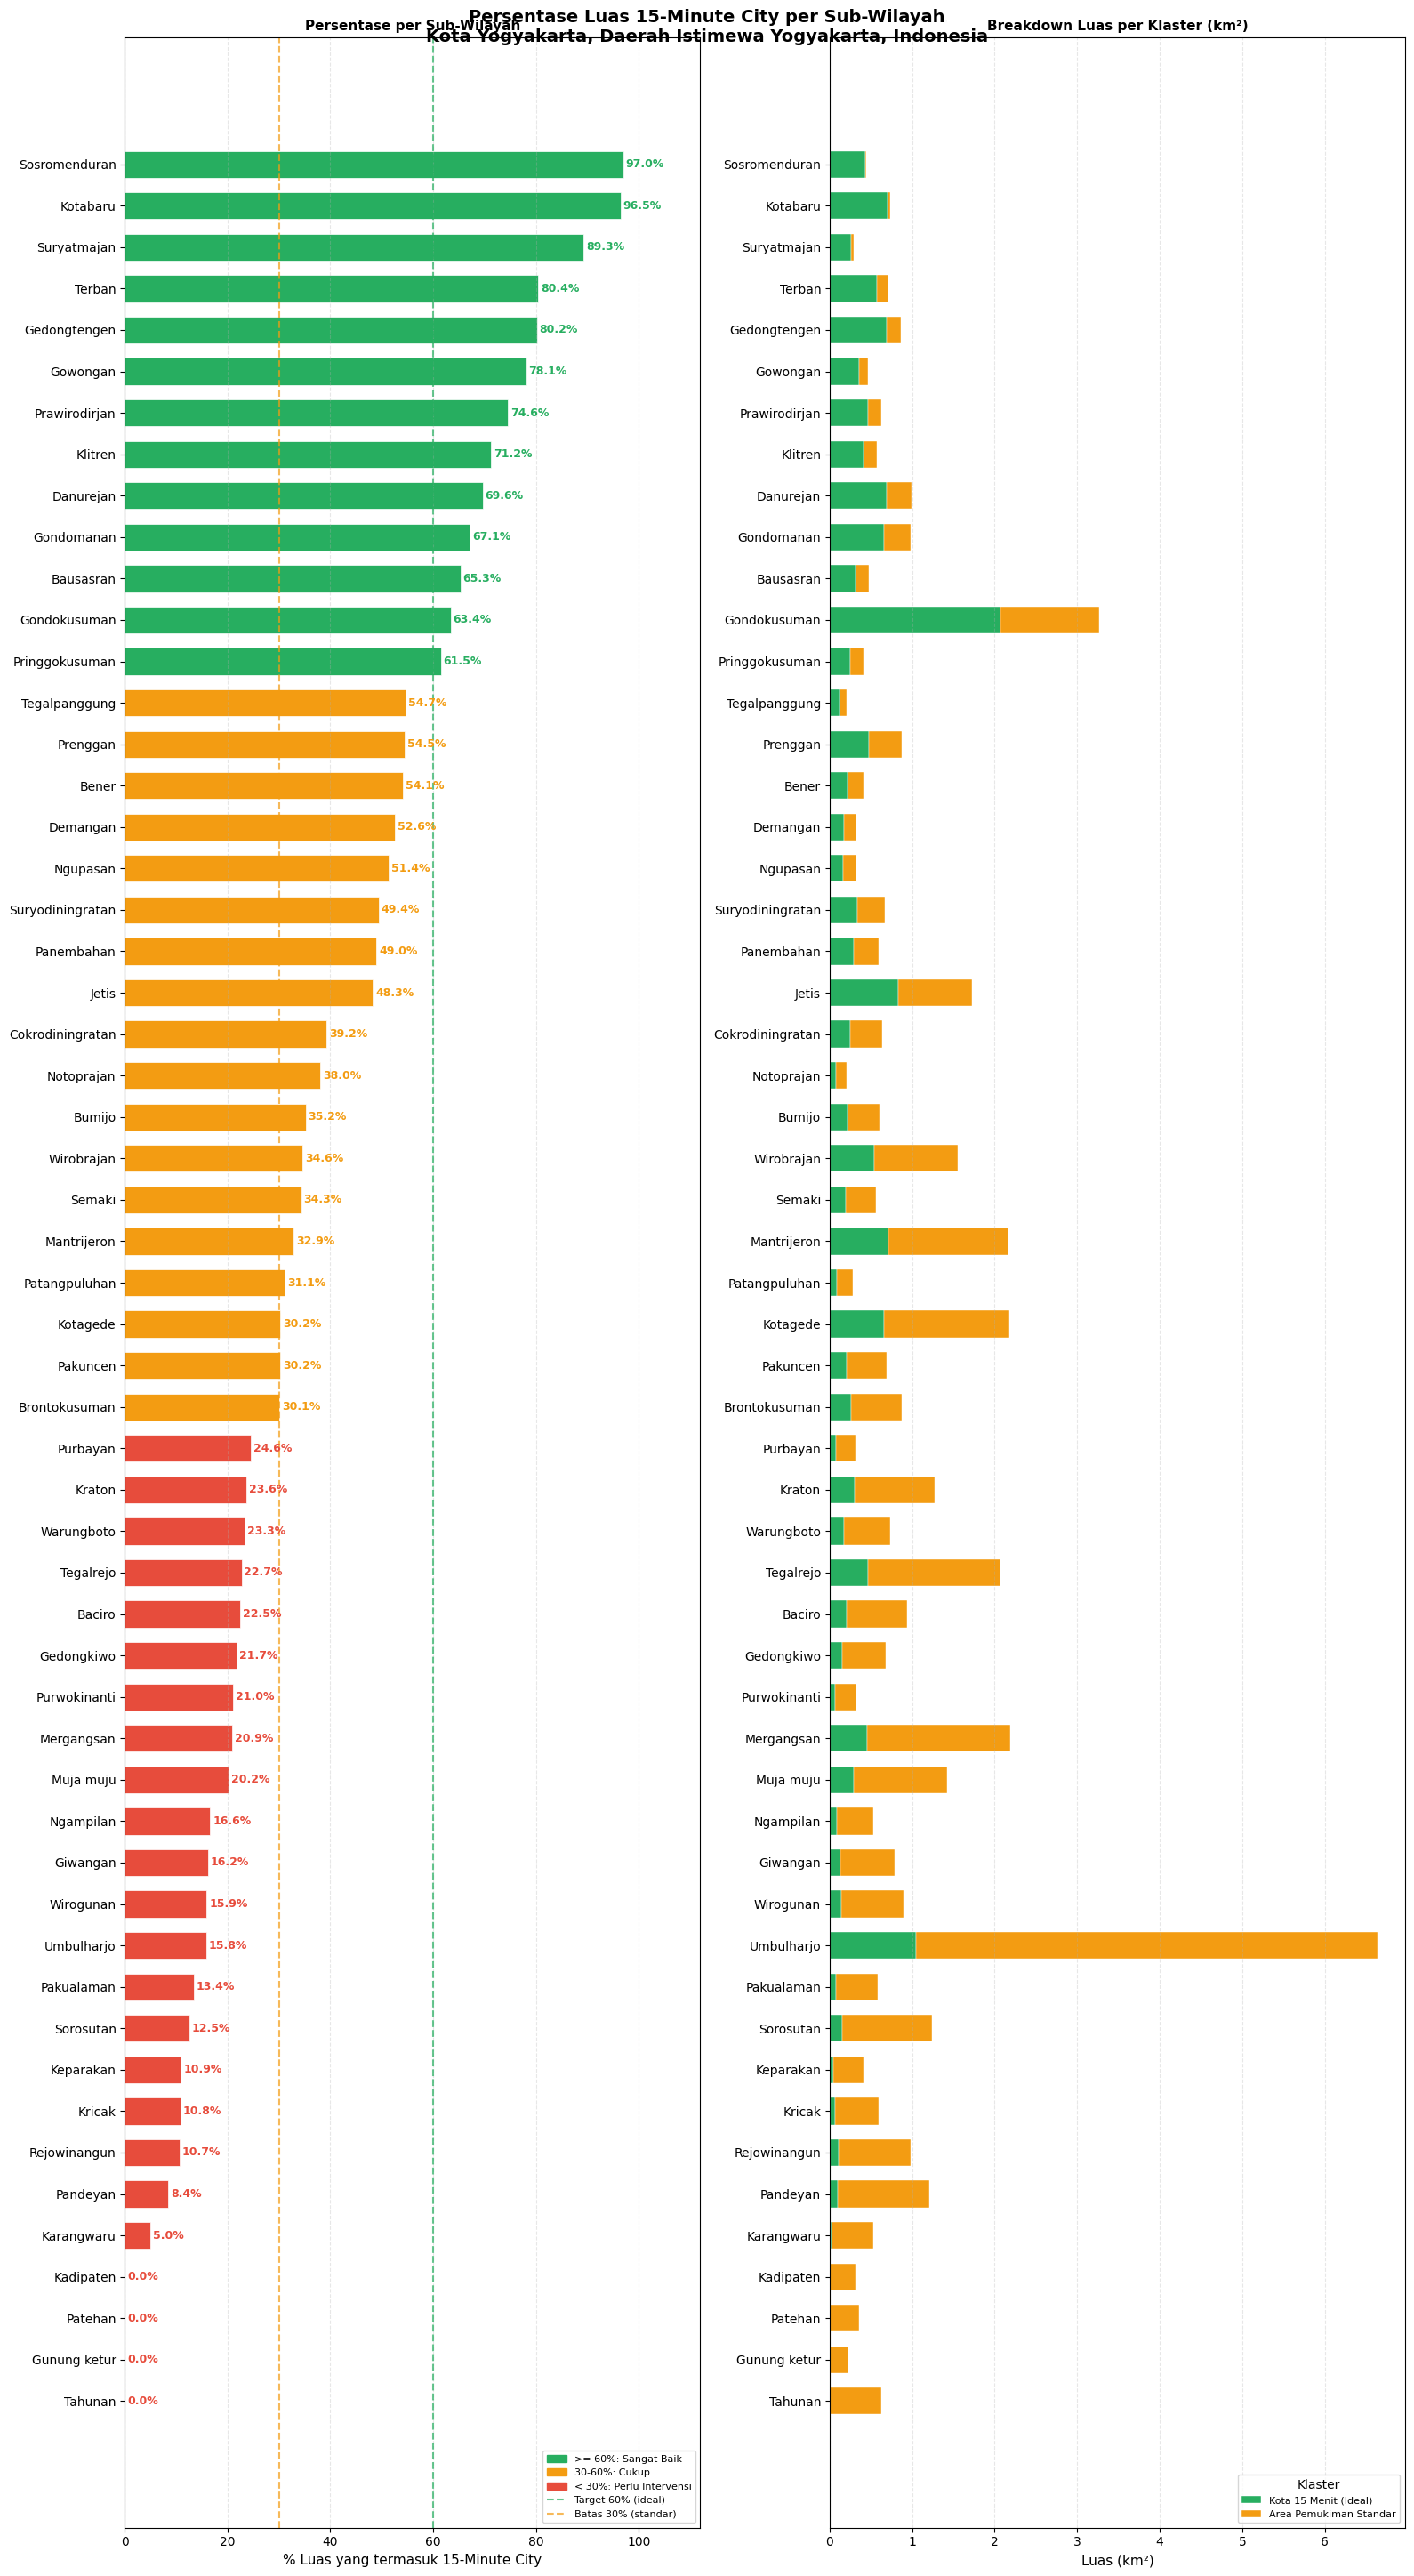

💾 outputs/figures/07_persentase_subwilayah.png tersimpan


In [25]:
# ============================================================
# VISUALISASI: Bar Chart Persentase per Sub-Wilayah
# ============================================================
df_plot = df_pct.sort_values('pct_15min_city', ascending=True).copy()

fig, axes = plt.subplots(1, 2, figsize=(16, max(6, len(df_plot)*0.5 + 2)))
fig.suptitle(
    f'Persentase Luas 15-Minute City per Sub-Wilayah\n{PLACE_NAME}',
    fontsize=14, fontweight='bold'
)

# ── Horizontal bar chart ─────────────────────────────────────
ax1 = axes[0]
colors_bar = [
    '#27AE60' if v >= 60 else
    '#F39C12' if v >= 30 else
    '#E74C3C'
    for v in df_plot['pct_15min_city']
]
bars = ax1.barh(
    df_plot['nama_sub'], df_plot['pct_15min_city'],
    color=colors_bar, edgecolor='white', linewidth=0.5, height=0.65
)

# Nilai di ujung bar
for bar, val in zip(bars, df_plot['pct_15min_city']):
    ax1.text(
        bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
        f'{val:.1f}%', va='center', fontsize=9, fontweight='bold',
        color='#27AE60' if val >= 60 else '#F39C12' if val >= 30 else '#E74C3C'
    )

# Garis target 60% & 30%
line_target = ax1.axvline(x=60, color='#27AE60', linestyle='--', alpha=0.7, lw=1.5, label='Target 60% (ideal)')
line_std    = ax1.axvline(x=30, color='#F39C12', linestyle='--', alpha=0.7, lw=1.5, label='Batas 30% (standar)')
ax1.set_xlim(0, 112)
ax1.set_xlabel('% Luas yang termasuk 15-Minute City', fontsize=11)
ax1.set_title('Persentase per Sub-Wilayah', fontsize=11, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='x', linestyle='--')

# Gabungkan legend garis target & warna kategori dalam satu legend
leg_patches = [
    mpatches.Patch(color='#27AE60', label='>= 60%: Sangat Baik'),
    mpatches.Patch(color='#F39C12', label='30-60%: Cukup'),
    mpatches.Patch(color='#E74C3C', label='< 30%: Perlu Intervensi'),
    line_target,
    line_std,
]
ax1.legend(handles=leg_patches, fontsize=8, loc='lower right')

# ── Stacked bar: breakdown per klaster ───────────────────────
ax2 = axes[1]
all_labels = [cluster_names[k] for k in sorted_clusters if any(lbl == cluster_names[k] for row in df_pct['cluster_detail'] for lbl in row.keys())]
label_color_map = {v: cluster_colors[k] for k, v in cluster_names.items()}

bottom = np.zeros(len(df_plot))
for lbl in all_labels:
    vals = df_plot['cluster_detail'].apply(lambda d: d.get(lbl, 0)).values
    ax2.barh(
        df_plot['nama_sub'], vals,
        left=bottom, label=lbl,
        color=label_color_map.get(lbl, '#CCCCCC'),
        edgecolor='white', linewidth=0.3, height=0.65
    )
    bottom += vals

ax2.set_xlabel('Luas (km²)', fontsize=11)
ax2.set_title('Breakdown Luas per Klaster (km²)', fontsize=11, fontweight='bold')
ax2.legend(fontsize=8, loc='lower right', title='Klaster')
ax2.grid(True, alpha=0.3, axis='x', linestyle='--')

plt.tight_layout()
# plt.savefig('outputs/figures/07_persentase_subwilayah.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 outputs/figures/07_persentase_subwilayah.png tersimpan')

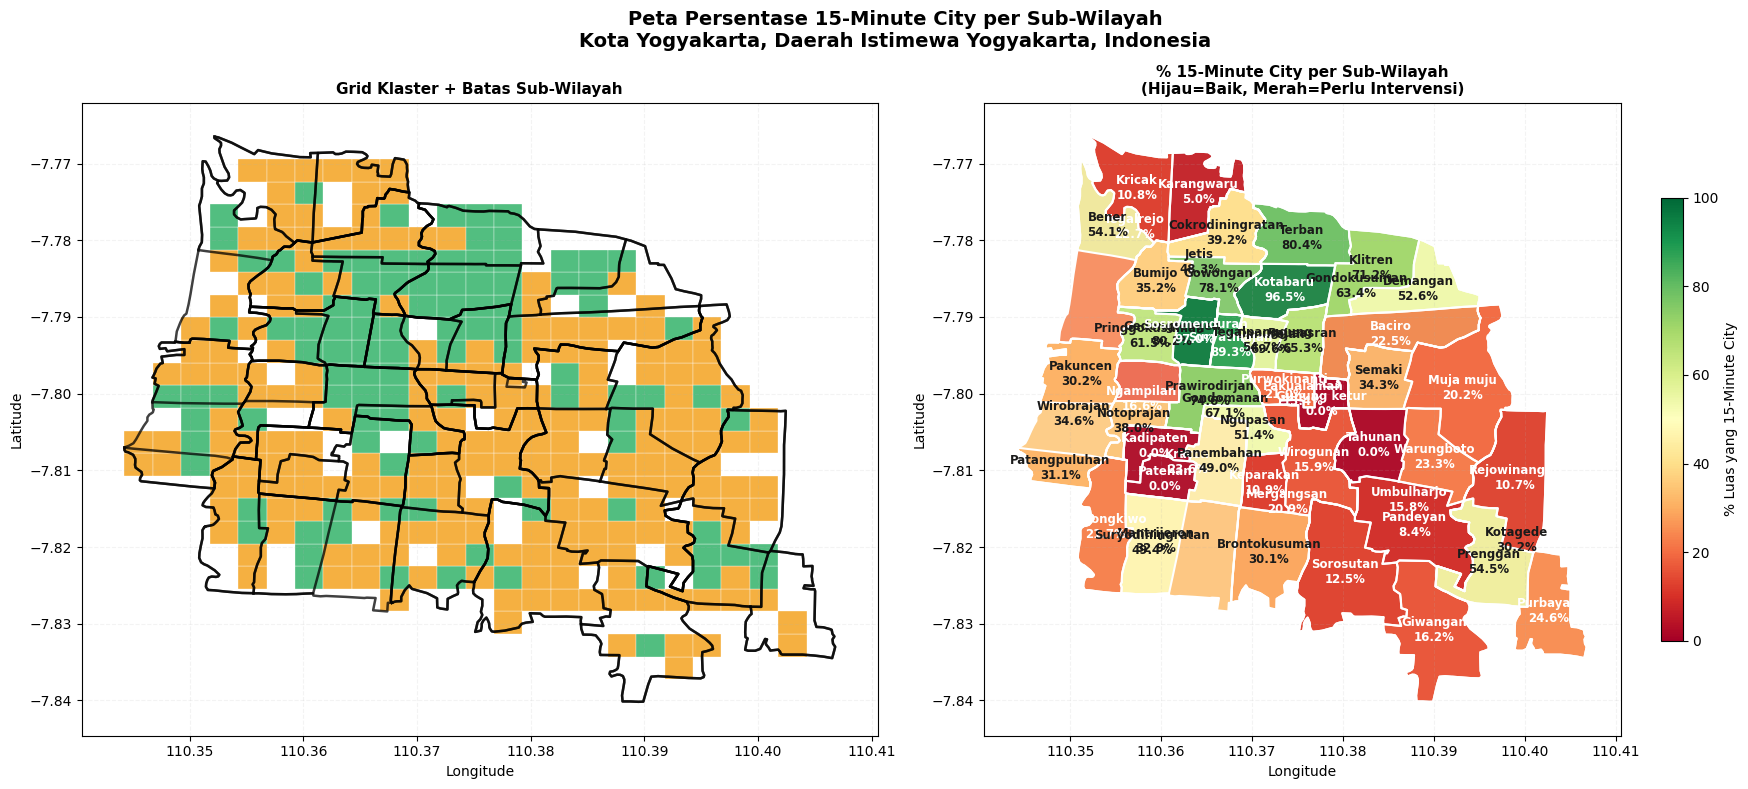

💾 outputs/figures/08_peta_persentase.png tersimpan


In [26]:
# ============================================================
# VISUALISASI: Peta Choropleth Persentase per Sub-Wilayah
# ============================================================
import matplotlib.cm as cm
import matplotlib.colors as mcolors

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
fig.suptitle(
    f'Peta Persentase 15-Minute City per Sub-Wilayah\n{PLACE_NAME}',
    fontsize=14, fontweight='bold'
)

# Gunakan bounding box sub-wilayah daratan agar peta tidak 80% kosong oleh laut
sub_lon_min, sub_lat_min, sub_lon_max, sub_lat_max = gdf_sub.total_bounds
pad_lon = (sub_lon_max - sub_lon_min) * 0.06
pad_lat = (sub_lat_max - sub_lat_min) * 0.06

# ── Kiri: Grid klaster + batas sub-wilayah ───────────────────
ax1 = axes[0]
for _, row in df_grid.iterrows():
    ax1.add_patch(plt.Rectangle(
        (row['lon_min'], row['lat_min']),
        row['lon_max']-row['lon_min'], row['lat_max']-row['lat_min'],
        lw=0.3, ec='white', fc=row['cluster_color'], alpha=0.8
    ))

# Overlay batas sub-wilayah
for _, sub in gdf_sub.iterrows():
    try:
        geom  = sub.geometry
        polys = list(geom.geoms) if geom.geom_type=='MultiPolygon' else [geom]
        for p in polys:
            xs, ys = zip(*list(p.exterior.coords))
            ax1.plot(xs, ys, color='black', lw=1.8, alpha=0.75)
    except: pass

ax1.set_xlim(sub_lon_min - pad_lon, sub_lon_max + pad_lon)
ax1.set_ylim(sub_lat_min - pad_lat, sub_lat_max + pad_lat)
ax1.set_title('Grid Klaster + Batas Sub-Wilayah', fontsize=11, fontweight='bold')
ax1.set_xlabel('Longitude'); ax1.set_ylabel('Latitude')
ax1.grid(True, alpha=0.15, ls='--')

# ── Kanan: Choropleth % ideal per sub-wilayah ────────────────
ax2 = axes[1]
cmap_pct  = cm.RdYlGn
norm_pct  = mcolors.Normalize(vmin=0, vmax=100)

# Gabungkan df_pct ke gdf_sub (sertakan luas_total_km2 untuk peta interaktif berikutnya)
gdf_sub_plot = gdf_sub.merge(
    df_pct[['sub_id', 'pct_15min_city', 'luas_ideal_km2', 'luas_total_km2']],
    on='sub_id', how='left'
)

for _, sub in gdf_sub_plot.iterrows():
    pct   = sub.get('pct_15min_city', 0) or 0
    color = cmap_pct(norm_pct(pct))
    try:
        geom  = sub.geometry
        polys = list(geom.geoms) if geom.geom_type=='MultiPolygon' else [geom]
        for p in polys:
            xs, ys = zip(*list(p.exterior.coords))
            ax2.fill(xs, ys, color=color, alpha=0.85, linewidth=0)
            ax2.plot(xs, ys, color='white', lw=1.5)
    except: pass

    # Label nama + persentase di tengah sub-wilayah
    try:
        cx = sub.geometry.centroid.x
        cy = sub.geometry.centroid.y
        ax2.text(cx, cy, f"{sub['nama_sub']}\n{pct:.1f}%",
                 ha='center', va='center', fontsize=8.5,
                 fontweight='bold',
                 color='white' if (pct < 25 or pct > 85) else '#1a1a1a',
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='none', edgecolor='none'))
    except: pass

sm = cm.ScalarMappable(cmap=cmap_pct, norm=norm_pct)
plt.colorbar(sm, ax=ax2, shrink=0.7, label='% Luas yang 15-Minute City')
ax2.set_xlim(sub_lon_min - pad_lon, sub_lon_max + pad_lon)
ax2.set_ylim(sub_lat_min - pad_lat, sub_lat_max + pad_lat)
ax2.set_title('% 15-Minute City per Sub-Wilayah\n(Hijau=Baik, Merah=Perlu Intervensi)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Longitude'); ax2.set_ylabel('Latitude')
ax2.grid(True, alpha=0.15, ls='--')

plt.tight_layout()
# plt.savefig('outputs/figures/08_peta_persentase.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 outputs/figures/08_peta_persentase.png tersimpan')

In [27]:
# ============================================================
# PETA FOLIUM INTERAKTIF: Grid + Persentase per Sub-Wilayah
# ============================================================
m2 = folium.Map(location=[CENTER_LAT, CENTER_LON], zoom_start=11,
                tiles='CartoDB positron')

# ── Layer 1: Grid klaster (default on) ───────────────────────
layer_grid = folium.FeatureGroup(name='Grid Klaster', show=True)
for _, row in df_grid.iterrows():
    tip = f"""
    <b>Zona {row['zona_id']}</b><br>
    🏥 {row['n_kesehatan']}  🎓 {row['n_pendidikan']}
    🌳 {row['n_rth_taman']}  🛒 {row['n_ekonomi']}
    🚌 {row['n_transportasi']}<br>
    Total: <b>{row['total_fasilitas']}</b><br>
    <b style='color:{row["cluster_color"]}'>{row['cluster_label']}</b>
    """
    folium.Rectangle(
        bounds=[[row['lat_min'],row['lon_min']],[row['lat_max'],row['lon_max']]],
        color='white', weight=0.4, fill=True,
        fill_color=row['cluster_color'], fill_opacity=0.65,
        tooltip=folium.Tooltip(tip)
    ).add_to(layer_grid)
layer_grid.add_to(m2)

# ── Layer 2: Choropleth % per sub-wilayah ────────────────────
layer_pct = folium.FeatureGroup(name='% 15-Minute City per Sub-Wilayah', show=True)

def pct_to_color(pct):
    """Konversi persentase ke warna hex."""
    if pct >= 70:   return '#1a9850'
    elif pct >= 50: return '#66bd63'
    elif pct >= 30: return '#fee08b'
    elif pct >= 15: return '#f46d43'
    else:           return '#d73027'

for _, sub in gdf_sub_plot.iterrows():
    pct   = float(sub.get('pct_15min_city', 0) or 0)
    luas  = float(sub.get('luas_ideal_km2', 0) or 0)
    color = pct_to_color(pct)

    tip_sub = f"""
    <b>{sub['nama_sub']}</b><br>
    <hr style='margin:3px 0'>
    Luas total grid : {sub.get('luas_total_km2', 0):.1f} km²<br>
    Luas ideal      : {luas:.1f} km²<br>
    <b style='font-size:16px;color:{color}'>{pct:.1f}%</b>
    sudah 15-Minute City<br><br>
    <span style='color:#888;font-size:11px'>
    {'🟢 Sangat Baik' if pct>=70 else '🟡 Cukup' if pct>=30 else '🔴 Perlu Intervensi'}
    </span>
    """
    try:
        folium.GeoJson(
            sub.geometry.__geo_interface__,
            style_function=lambda f, c=color: {
                'fillColor': c, 'color': 'black', 'weight': 2.0, 'fillOpacity': 0.35
            },
            tooltip=folium.Tooltip(tip_sub)
        ).add_to(layer_pct)
    except: pass

layer_pct.add_to(m2)

# ── Legend ───────────────────────────────────────────────────
legend_html = f"""
<div style='position:fixed;bottom:30px;left:30px;z-index:1000;
     background:white;padding:14px;border-radius:8px;
     border:1px solid #ccc;font-family:Arial;font-size:12px;
     box-shadow:2px 2px 6px rgba(0,0,0,.15);'>
<b>% 15-Minute City</b><br><br>
<span style='background:#1a9850;padding:1px 8px;border-radius:2px'>&nbsp;</span> ≥ 70% Sangat Baik<br>
<span style='background:#66bd63;padding:1px 8px;border-radius:2px'>&nbsp;</span> 50-70% Baik<br>
<span style='background:#fee08b;padding:1px 8px;border-radius:2px'>&nbsp;</span> 30-50% Cukup<br>
<span style='background:#f46d43;padding:1px 8px;border-radius:2px'>&nbsp;</span> 15-30% Rendah<br>
<span style='background:#d73027;padding:1px 8px;border-radius:2px'>&nbsp;</span> &lt; 15% Kritis<br>
<br><small style='color:#888'>{PLACE_NAME}</small>
</div>
"""
m2.get_root().html.add_child(folium.Element(legend_html))
folium.LayerControl(collapsed=False).add_to(m2)

# m2.save('outputs/maps/09_peta_interaktif_persentase.html')
# print('💾 outputs/maps/09_peta_interaktif_persentase.html tersimpan')
print('   Hover ke sub-wilayah untuk lihat persentase detail')
m2


   Hover ke sub-wilayah untuk lihat persentase detail


In [28]:
# ============================================================
# TABEL RINGKASAN & EXPORT CSV
# ============================================================
print('=' * 65)
print(f'  RINGKASAN PERSENTASE 15-MINUTE CITY')
print(f'  {PLACE_NAME}')
print('=' * 65)

df_summary = df_pct[['nama_sub','luas_total_km2','luas_ideal_km2',
                      'pct_15min_city','n_sel_ideal','n_sel_total']].copy()
df_summary.columns = ['Sub-Wilayah','Luas Total (km²)','Luas Ideal (km²)',
                       '% 15-Min City','Grid Ideal','Grid Total']
df_summary = df_summary.sort_values('% 15-Min City', ascending=False)

# Kategori
def kategori(pct):
    if pct >= 70:  return '🟢 Sangat Baik'
    elif pct >= 50: return '🟡 Baik'
    elif pct >= 30: return '🟠 Cukup'
    elif pct >= 15: return '🔴 Rendah'
    else:           return '⛔ Kritis'

df_summary['Status'] = df_summary['% 15-Min City'].apply(kategori)

print(df_summary.to_string(index=False))
print()

# Statistik kota keseluruhan
total_luas   = df_summary['Luas Total (km²)'].sum()
total_ideal  = df_summary['Luas Ideal (km²)'].sum()
pct_kota     = total_ideal / total_luas * 100 if total_luas > 0 else 0
print(f'  TOTAL KOTA:')
print(f'  Luas total grid  : {total_luas:.1f} km²')
print(f'  Luas 15-Min City : {total_ideal:.1f} km²')
print(f'  % 15-Min City    : {pct_kota:.1f}% dari seluruh {PLACE_NAME}')

# Export
# df_pct.drop(columns=['cluster_detail'], errors='ignore').to_csv(
#     'data/processed/hasil_persentase_subwilayah.csv', index=False
# )
print()
df_summary


  RINGKASAN PERSENTASE 15-MINUTE CITY
  Kota Yogyakarta, Daerah Istimewa Yogyakarta, Indonesia
     Sub-Wilayah  Luas Total (km²)  Luas Ideal (km²)  % 15-Min City  Grid Ideal  Grid Total        Status
   Sosromenduran              0.45              0.43           97.0           8           9 🟢 Sangat Baik
        Kotabaru              0.73              0.71           96.5          13          14 🟢 Sangat Baik
     Suryatmajan              0.30              0.26           89.3           6           8 🟢 Sangat Baik
          Terban              0.71              0.57           80.4           9          11 🟢 Sangat Baik
    Gedongtengen              0.86              0.69           80.2          10          14 🟢 Sangat Baik
        Gowongan              0.46              0.36           78.1           8          10 🟢 Sangat Baik
   Prawirodirjan              0.62              0.46           74.6           6           9 🟢 Sangat Baik
         Klitren              0.57              0.41     

,Sub-Wilayah,Luas Total (km²),Luas Ideal (km²),% 15-Min City,Grid Ideal,Grid Total,Status
44,Sosromenduran,0.45,0.43,97.0,8,9,🟢 Sangat Baik
33,Kotabaru,0.73,0.71,96.5,13,14,🟢 Sangat Baik
52,Suryatmajan,0.30,0.26,89.3,6,8,🟢 Sangat Baik
25,Terban,0.71,0.57,80.4,9,11,🟢 Sangat Baik
20,Gedongtengen,0.86,0.69,80.2,10,14,🟢 Sangat Baik
42,Gowongan,0.46,0.36,78.1,8,10,🟢 Sangat Baik
36,Prawirodirjan,0.62,0.46,74.6,6,9,🟢 Sangat Baik
26,Klitren,0.57,0.41,71.2,7,10,🟢 Sangat Baik
15,Danurejan,0.99,0.69,69.6,13,20,🟡 Baik
17,Gondomanan,0.98,0.66,67.1,9,14,🟡 Baik


---
## ✅ Ringkasan Implementasi

| Komponen | Cara Implementasi | Library |
|---|---|---|
| **Data Collection** | OSMnx → langsung dari OpenStreetMap | OSMnx |
| **StandardScaler** | Z-Score manual: `(x−μ)/σ` | NumPy |
| **K-Means** | E-step + M-step + K-Means++ init + multi-restart | NumPy |
| **Elbow Method** | WCSS per K, plot siku | NumPy |
| **Silhouette Score** | a(i), b(i), s(i) manual | NumPy |
| **Peta Choropleth** | Grid rectangle per zona | Matplotlib |
| **Peta Interaktif** | Folium rectangle + tooltip hover | Folium |

### 🔧 Tips Troubleshooting

**Error `InsufficientResponseError`:** Nama kota tidak ditemukan di OSM.  
→ Coba: `"Kota Yogyakarta, Daerah Istimewa Yogyakarta, Indonesia"`

**POI sangat sedikit (< 10 titik per kategori):**  
→ Tambah tag di `POI_TAGS`, atau perbesar `RADIUS_METER`

**Proses terlalu lama:**  
→ Kurangi `GRID_SIZE` (misal 6×6) atau kurangi `RADIUS_METER`